# Employee Turnover Analytics

## Machine Learning Course-End Project

### Business Problem

Portobello Tech wants to understand why employees leave the
organization and develop machine learning models to predict
employee turnover.

### Project Objectives

1. Assess data quality and identify missing values.
2. Explore relationships between employee characteristics and turnover.
3. Identify employee groups using K-means clustering.
4. Prepare data and address class imbalance using SMOTE.
5. Train and evaluate classification models.
6. Compare model performance using appropriate evaluation metrics.
7. Predict employee turnover probabilities.
8. Recommend retention strategies based on employee risk levels.

### Target Variable

The target variable is `left`.

- 0 = Employee stayed
- 1 = Employee left

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
# Define the path to out project data set
data_path = Path(
    "../data/HR_comma_sep.csv"
)

# Load the data set into a pandas DataFrame
df = pd.read_csv(data_path)

# Display the first 5 rows of the DataFrame
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
# Check the number of rows and columns
df.shape

(14999, 10)

In [4]:
# Display information about the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [5]:
# Count missing values in each column
df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [6]:
# Count rows that are exact duplicates
df.duplicated().sum()

np.int64(3008)

In [7]:
# Count employees who stayed versus employees who left
df["left"].value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

In [8]:
# Calculate the percentage of each employee outcome
df["left"].value_counts(normalize=True) * 100

left
0    76.191746
1    23.808254
Name: proportion, dtype: float64

## Data Quality Assessment

### Dataset Overview

The Employee Turnover dataset contains 14,999 observations
and 10 columns representing employee characteristics,
workplace conditions, and turnover status.

The dataset consists of:
- 2 floating-point columns
- 6 integer columns
- 2 string columns

The target variable is `left`, where:
- 0 indicates an employee remained with the company.
- 1 indicates an employee left the company.

### Missing Value Analysis

A missing-value assessment was performed using
`df.isnull().sum()`.

All 10 columns contain 14,999 non-null values, indicating
that no missing values were detected.

Therefore, no missing-value imputation or removal is
required based on the initial assessment.

### Duplicate Record Analysis

Duplicate records were identified using
`df.duplicated().sum()`.

The analysis identified 3,008 exact duplicate rows,
representing approximately 20.05% of the dataset.

However, the dataset does not contain unique employee
identifiers. Therefore, identical records may represent
different employees with matching characteristics.

Duplicate records have not been removed at this stage.
Further analysis will determine how duplicate records
are distributed across employee turnover categories
before deciding whether deduplication is appropriate.

### Employee Turnover Distribution

The distribution of the target variable was examined
using `value_counts()`.

Results:

- Employees who stayed: 11,428 (76.19%)
- Employees who left: 3,571 (23.81%)

The dataset demonstrates class imbalance, with employees
who stayed representing approximately three-quarters
of all observations.

This imbalance is important because a classification
model could achieve relatively high accuracy by
primarily predicting the majority class.

The project requires the Synthetic Minority
Oversampling Technique (SMOTE) to address class
imbalance during model training.

SMOTE will be applied only to training data to
prevent data leakage into the test set.

### Categorical Features

Two columns contain categorical information:

- `sales`: Employee department
- `salary`: Employee salary category

These features will require numerical encoding before
training classification models.

### Initial Findings

The initial data quality assessment identified:

1. No missing values requiring treatment.
2. A significant number of exact duplicate records
   requiring further investigation.
3. Class imbalance in the employee turnover target.
4. Two categorical features requiring encoding.

The original dataset will remain unchanged while
additional exploratory analysis is performed.

In [9]:
# Identify exact duplicate rows
duplicate_mask = df.duplicated()

# Count duplicates among employees who stayed and left
df.loc[duplicate_mask, "left"].value_counts()

left
1    1580
0    1428
Name: count, dtype: int64

In [10]:
# Create a separate DataFrame without exact duplicates
df_unique = df.drop_duplicates().copy()

# Compare dataset sizes
print("Original records:", len(df))
print("Unique records:", len(df_unique))

# Compare turnover percentages
print("\nOriginal turnover distribution:")
print(df["left"].value_counts(normalize=True) * 100)

print("\nUnique-record turnover distribution:")
print(df_unique["left"].value_counts(normalize=True) * 100)

Original records: 14999
Unique records: 11991

Original turnover distribution:
left
0    76.191746
1    23.808254
Name: proportion, dtype: float64

Unique-record turnover distribution:
left
0    83.39588
1    16.60412
Name: proportion, dtype: float64


### Duplicate Record Investigation

Further analysis was performed to determine how duplicate
records were distributed across employee turnover classes.

Of the 3,008 duplicate rows:

- 1,580 belonged to employees who left.
- 1,428 belonged to employees who stayed.

Duplicate rows were disproportionately represented among
employees who left the organization.

After removing exact duplicates for comparison, the dataset
contained 11,991 unique rows.

The employee turnover distribution changed as follows:

| Employee Status | Original Dataset | Unique Records |
|---|---:|---:|
| Stayed | 76.19% | 83.40% |
| Left | 23.81% | 16.60% |

The turnover rate decreased by approximately 7.20 percentage
points after deduplication.

### Data Cleaning Decision

The analysis revealed that removing exact duplicates
substantially changes the target class distribution.

Because the dataset does not contain unique employee
identifiers, identical rows cannot conclusively be identified
as duplicate employees.

For this coursework project, exact duplicate rows will be
excluded from the primary modeling dataset to reduce the
risk of identical records appearing in both training and
test sets.

The original DataFrame (`df`) will remain unchanged,
while `df_unique` will be used for subsequent analysis
and modeling.

This decision may remove legitimate employees with
identical characteristics and may change the population
represented by the model. This limitation will be
acknowledged when interpreting results.

Class imbalance will be addressed using SMOTE on training
data only.

In [11]:
# Preserve the original dataset in df

# Create our working dataset from unique records
df_clean = df_unique.copy()

# Reset row indices after removing duplicates
df_clean.reset_index(drop=True, inplace=True)

# Verify the cleaned dataset
print("Working dataset shape:", df_clean.shape)

print("\nRemaining duplicate rows:")
print(df_clean.duplicated().sum())

Working dataset shape: (11991, 10)

Remaining duplicate rows:
0


## Exploratory Data Analysis

### Correlation Analysis

The objective of this analysis is to identify linear
relationships between numerical employee characteristics
and employee turnover.

A Pearson correlation matrix will be calculated and
visualized using a heatmap.

In [12]:
# Select only numerical columns from our working dataset
numeric_df = df_clean.select_dtypes(include=["number"])

# Display the numerical column names
numeric_df.columns.tolist()

['satisfaction_level',
 'last_evaluation',
 'number_project',
 'average_montly_hours',
 'time_spend_company',
 'Work_accident',
 'left',
 'promotion_last_5years']

In [13]:
# Calculate Pearson correlation coefficients
correlation_matrix = numeric_df.corr(method="pearson")

# Display the correlation matrix
correlation_matrix

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
satisfaction_level,1.000000,0.095186,-0.133246,-0.006252,-0.152915,0.039940,-0.350558,0.019789
last_evaluation,0.095186,1.000000,0.270256,0.264678,0.096829,-0.005695,0.013520,-0.007206
number_project,-0.133246,0.270256,1.000000,0.331516,0.188837,-0.005612,0.030928,-0.000544
average_montly_hours,-0.006252,0.264678,0.331516,1.000000,0.102875,-0.012860,0.070409,-0.004964
time_spend_company,-0.152915,0.096829,0.188837,0.102875,1.000000,0.000003,0.173295,0.056828
Work_accident,0.039940,-0.005695,-0.005612,-0.012860,0.000003,1.000000,-0.125436,0.029852
left,-0.350558,0.013520,0.030928,0.070409,0.173295,-0.125436,1.000000,-0.044657
promotion_last_5years,0.019789,-0.007206,-0.000544,-0.004964,0.056828,0.029852,-0.044657,1.000000


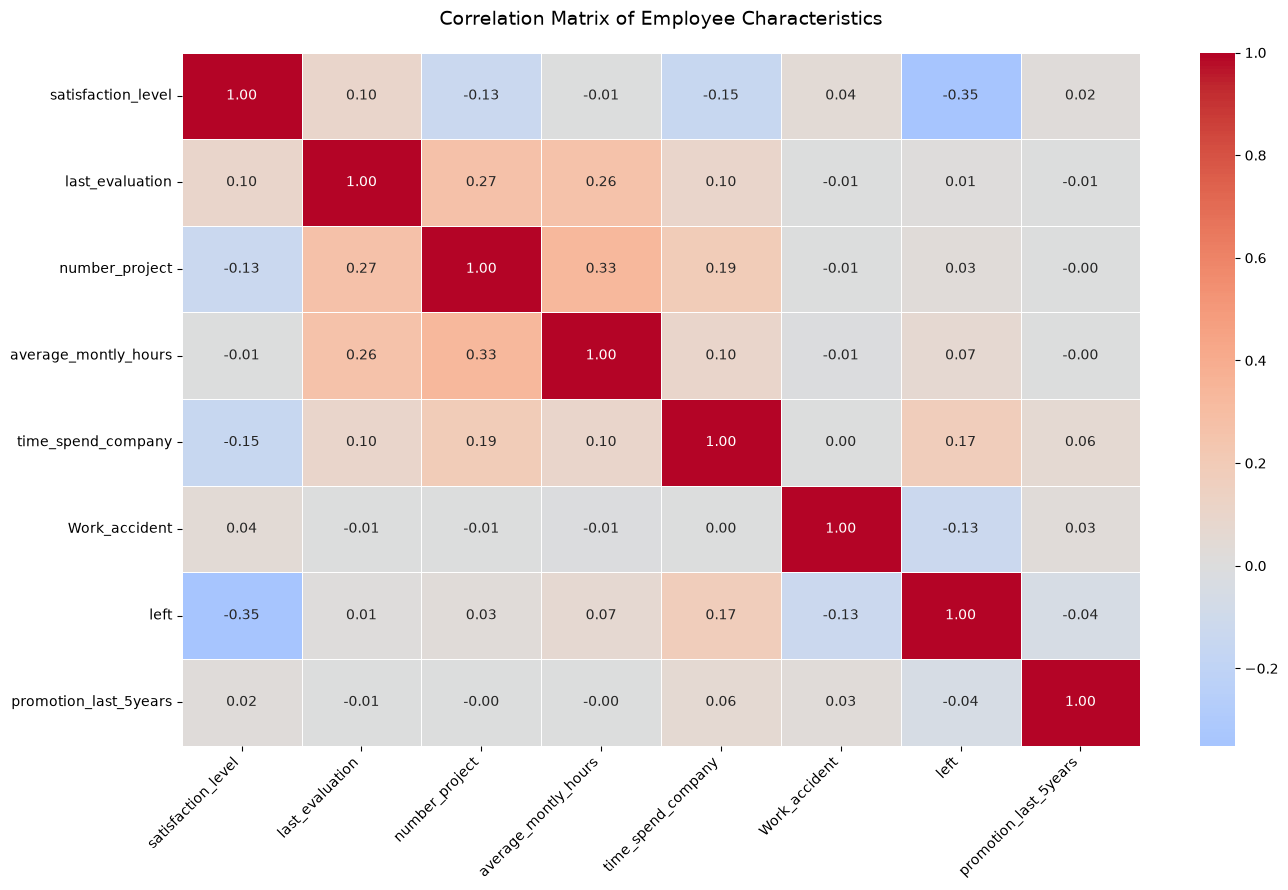

In [14]:
# Set the figure dimensions
plt.figure(figsize=(14, 9))

# Create the correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

# Add a descriptive title
plt.title(
    "Correlation Matrix of Employee Characteristics",
    fontsize=14,
    pad=20
)

# Rotate the X-axis labels diagonally
plt.xticks(rotation=45, ha="right")

# Keep the Y-axis labels horizontal
plt.yticks(rotation=0)

# Adjust spacing to prevent overlapping labels
plt.tight_layout()

# Display the heatmap
plt.show()

### Correlation Analysis Findings

A Pearson correlation matrix was calculated to examine
linear relationships between numerical employee
characteristics and employee turnover.

The analysis was performed on the cleaned dataset
containing 11,991 unique records.

#### Relationship Between Satisfaction and Turnover

Employee satisfaction demonstrated the strongest
linear association with turnover among the numerical
predictors, with a correlation coefficient of -0.351.

This moderate negative relationship indicates that
employees with higher satisfaction scores generally
exhibited lower turnover.

The result suggests that employee satisfaction is
an important factor for further investigation.

#### Employee Tenure

Years spent at the company demonstrated a weak positive
correlation with turnover (r = 0.173).

This suggests that longer tenure is associated with
slightly higher turnover in the dataset.

Additional analysis is necessary to determine whether
turnover is concentrated within particular tenure groups.

#### Employee Workload

Average monthly working hours demonstrated a very weak
positive correlation with turnover (r = 0.070).

The number of projects also demonstrated a very weak
positive correlation (r = 0.031).

These results indicate limited overall linear
relationships with turnover.

However, nonlinear relationships may exist and will
require additional exploratory analysis.

#### Performance Evaluation

Employee evaluation scores demonstrated almost no
linear correlation with turnover (r = 0.014).

This does not necessarily indicate that performance
evaluations have no predictive value.

More complex relationships may exist between evaluation
scores, satisfaction, and employee turnover.

#### Promotions and Workplace Accidents

Promotions within the last five years demonstrated
a very weak negative correlation with turnover
(r = -0.045).

Workplace accidents demonstrated a weak negative
correlation (r = -0.125).

These relationships are observational and should not
be interpreted as causal.

#### Relationships Between Predictors

The number of projects and average monthly working
hours demonstrated a positive correlation (r = 0.332).

The number of projects and employee evaluation scores
also demonstrated a positive correlation (r = 0.270).

These relationships suggest that workload and
performance-related characteristics are associated.

#### Conclusion

Employee satisfaction demonstrated the strongest
linear relationship with turnover among the numerical
features analyzed.

Other variables showed weaker linear associations,
but they may still provide useful predictive
information through nonlinear relationships and
interactions.

Further exploratory analysis and machine learning
modeling are necessary to better understand the
factors associated with employee turnover.

Correlation does not establish causation.

### Employee Feature Distribution Analysis

The purpose of this analysis is to examine the
distributions of employee satisfaction, performance
evaluation scores, and average monthly working hours.

Distribution plots help identify patterns such as
skewness, concentration, multiple peaks, and possible
outliers.

These patterns may reveal relationships that are not
captured by Pearson correlation alone.

#### Employee Satisfaction Distribution

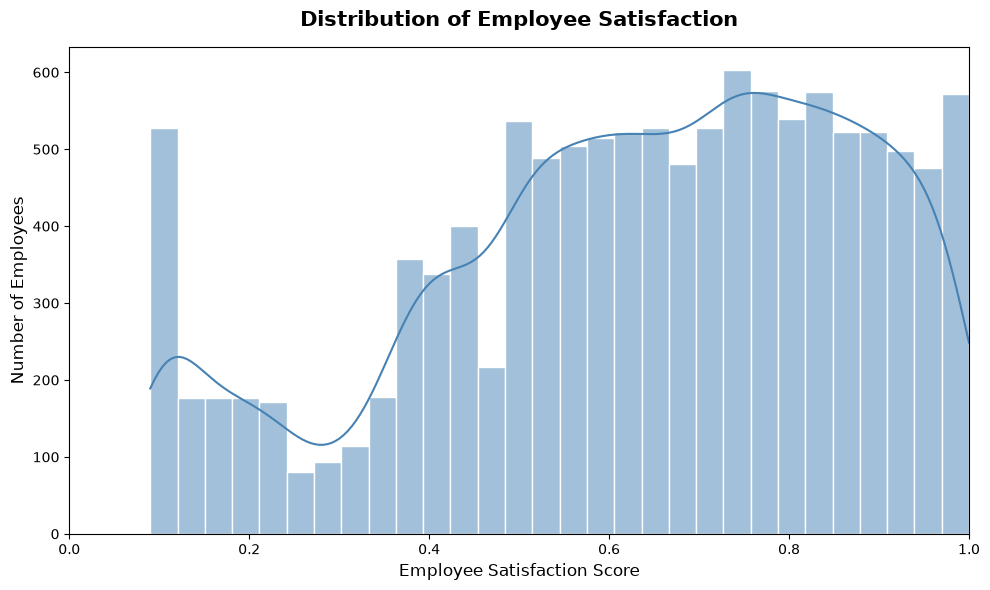

In [15]:
# Create a figure for the satisfaction distribution
plt.figure(figsize=(10, 6))

# Plot the distribution of employee satisfaction
sns.histplot(
    data=df_clean,
    x="satisfaction_level",
    bins=30,
    kde=True,
    color="steelblue",
    edgecolor="white"
)

# Add a descriptive title
plt.title(
    "Distribution of Employee Satisfaction",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Label the axes
plt.xlabel("Employee Satisfaction Score", fontsize=12)
plt.ylabel("Number of Employees", fontsize=12)

# Satisfaction scores range from 0 to 1
plt.xlim(0, 1)

# Improve spacing
plt.tight_layout()

# Display the plot
plt.show()

In [16]:
# Calculate descriptive statistics for employee satisfaction
df_clean["satisfaction_level"].describe()

count    11991.000000
mean         0.629658
std          0.241070
min          0.090000
25%          0.480000
50%          0.660000
75%          0.820000
max          1.000000
Name: satisfaction_level, dtype: float64

#### Employee Satisfaction Analysis Findings

Descriptive statistics were calculated for employee
satisfaction using the cleaned dataset containing
11,991 records.

The average satisfaction score was 0.630, while
the median was 0.660.

The median exceeded the mean, suggesting that lower
satisfaction values may be influencing the overall
average.

Employee satisfaction ranged from 0.09 to 1.00,
with a standard deviation of approximately 0.241.

The first quartile was 0.48, and the third quartile
was 0.82, producing an interquartile range of 0.34.

This indicates that the middle 50% of satisfaction
scores cover a relatively broad portion of the scale.

Previous correlation analysis identified a moderate
negative relationship between satisfaction and
employee turnover (r = -0.351).

Together, these findings suggest that satisfaction
is an important variable for further turnover
analysis and predictive modeling.

However, these descriptive statistics do not
establish a causal relationship between employee
satisfaction and turnover.

#### Employee Performance Evaluation Distribution

This analysis examines the distribution of employee
performance evaluation scores.

The objective is to understand how evaluation scores
are distributed across the workforce and identify
potential patterns that may warrant further
investigation.

Evaluation scores range from 0 to 1, with higher
values representing higher performance evaluations.

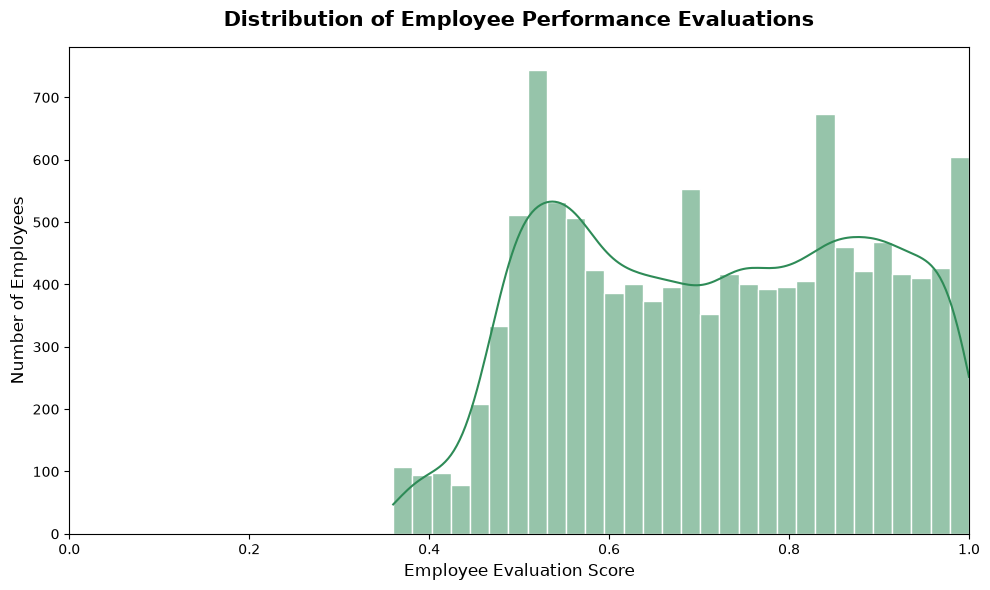

In [17]:
# Set the figure size
plt.figure(figsize=(10, 6))

# Plot employee evaluation scores
sns.histplot(
    data=df_clean,
    x="last_evaluation",
    bins=30,
    kde=True,
    color="seagreen",
    edgecolor="white"
)

# Add a title
plt.title(
    "Distribution of Employee Performance Evaluations",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Label the axes
plt.xlabel("Employee Evaluation Score", fontsize=12)
plt.ylabel("Number of Employees", fontsize=12)

# Set evaluation score range
plt.xlim(0, 1)

# Adjust layout
plt.tight_layout()

# Display the chart
plt.show()

In [18]:
# Calculate descriptive statistics for evaluation scores
df_clean["last_evaluation"].describe()

count    11991.000000
mean         0.716683
std          0.168343
min          0.360000
25%          0.570000
50%          0.720000
75%          0.860000
max          1.000000
Name: last_evaluation, dtype: float64

In [19]:
# Calculate average employee evaluation
mean_evaluation = df_clean["last_evaluation"].mean()

# Calculate median employee evaluation
median_evaluation = df_clean["last_evaluation"].median()

print(f"Mean Evaluation Score: {mean_evaluation:.3f}")
print(f"Median Evaluation Score: {median_evaluation:.3f}")

Mean Evaluation Score: 0.717
Median Evaluation Score: 0.720


#### Employee Performance Evaluation Findings

Descriptive statistical analysis was performed on
employee performance evaluation scores using the
cleaned dataset of 11,991 observations.

The mean evaluation score was approximately 0.717,
while the median was 0.720.

Although the mean and median are nearly identical, visual inspection of the histogram revealed multiple concentrations rather than a simple symmetric, bell-shaped distribution. This demonstrates that similar measures of central tendency do not necessarily indicate a symmetric distribution.

Evaluation scores ranged from 0.36 to 1.00, with
a standard deviation of approximately 0.168.

The first quartile was 0.57, while the third
quartile was 0.86, resulting in an interquartile
range of 0.29.

Compared with employee satisfaction, performance
evaluation scores demonstrated less variation.

Previous correlation analysis identified an
extremely weak positive linear relationship
between evaluation scores and employee turnover
(r = 0.014).

This suggests that evaluation scores alone have
limited linear association with turnover.

However, nonlinear patterns or interactions with
other employee characteristics may still exist.

Further analysis will investigate how performance
evaluation and satisfaction relate to employee
turnover, particularly through K-means clustering.

#### Performance Evaluation Distribution Interpretation

Visual inspection of the employee evaluation histogram
revealed a distribution with multiple concentrations.

A prominent concentration appeared around evaluation
scores of approximately 0.50–0.55, while another broader
concentration appeared around 0.85–0.90.

Most evaluation scores were concentrated above 0.50,
with relatively few observations below 0.45.

Although the mean (0.717) and median (0.720) were
nearly identical, the histogram demonstrated that
the distribution was not a simple symmetric,
bell-shaped distribution.

This highlights the importance of combining
descriptive statistical analysis with data
visualization when exploring employee characteristics.

The histogram includes employees who stayed and
employees who left. Therefore, the observed
distribution cannot independently establish a
relationship between evaluation scores and turnover.

Further analysis will investigate whether employees
with different performance evaluation scores exhibit
different turnover patterns.

#### Average Monthly Working Hours Distribution

This analysis examines the distribution of average monthly
working hours among employees at Portobello Tech.

The objective is to identify typical working-hour patterns,
variability in employee workloads, and potential concentrations
of employees working unusually low or high monthly hours.

Understanding workload distributions may help identify
employee groups that warrant further investigation
for possible turnover risk.

A histogram with a Kernel Density Estimation (KDE) curve
will be used to visualize the distribution, followed by
descriptive statistical analysis.

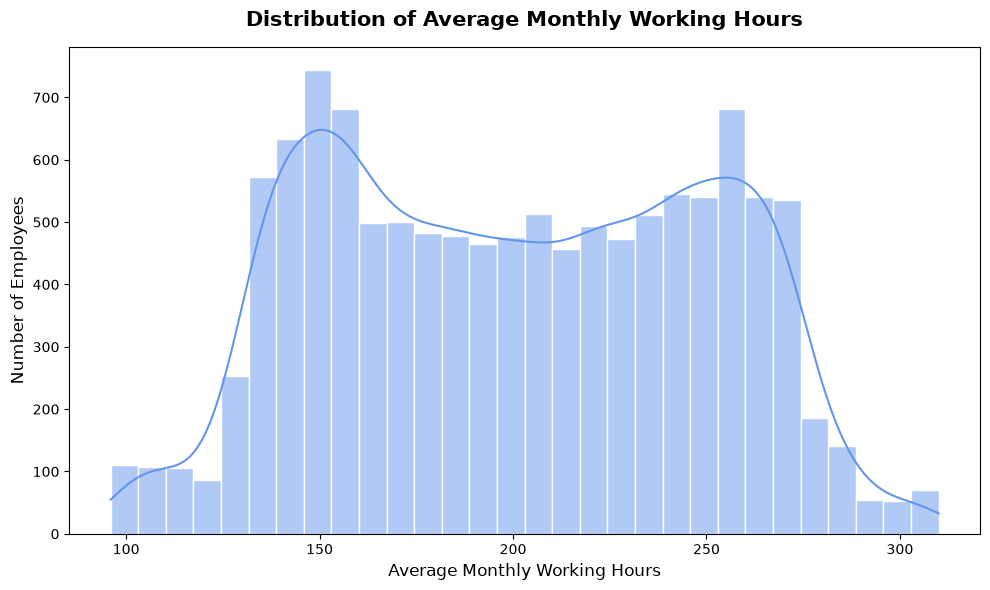

In [20]:
# Create a figure for average monthly working hours
plt.figure(figsize=(10, 6))

# Plot the distribution of average monthly working hours
sns.histplot(
    data=df_clean,
    x="average_montly_hours",
    bins=30,
    kde=True,
    color="cornflowerblue",
    edgecolor="white"
)

# Add a descriptive title
plt.title(
    "Distribution of Average Monthly Working Hours",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Label the axes
plt.xlabel("Average Monthly Working Hours", fontsize=12)
plt.ylabel("Number of Employees", fontsize=12)

# Improve chart readability
plt.tight_layout()

# Display the histogram
plt.show()

In [21]:
# Calculate descriptive statistics for monthly working hours
df_clean["average_montly_hours"].describe()

count    11991.000000
mean       200.473522
std         48.727813
min         96.000000
25%        157.000000
50%        200.000000
75%        243.000000
max        310.000000
Name: average_montly_hours, dtype: float64

In [22]:
# Calculate key working-hour statistics
mean_hours = df_clean["average_montly_hours"].mean()
median_hours = df_clean["average_montly_hours"].median()
min_hours = df_clean["average_montly_hours"].min()
max_hours = df_clean["average_montly_hours"].max()

# Display formatted results
print(f"Average Monthly Hours: {mean_hours:.2f}")
print(f"Median Monthly Hours: {median_hours:.2f}")
print(f"Minimum Monthly Hours: {min_hours}")
print(f"Maximum Monthly Hours: {max_hours}")

Average Monthly Hours: 200.47
Median Monthly Hours: 200.00
Minimum Monthly Hours: 96
Maximum Monthly Hours: 310


#### Average Monthly Working Hours Findings

Descriptive statistical analysis was performed on
average monthly working hours using the cleaned
dataset containing 11,991 observations.

The mean monthly working hours were approximately
200.47 hours, while the median was 200 hours.

The close relationship between the mean and median
indicates that the distribution is centered near
200 hours per month.

However, visual inspection of the histogram revealed
two prominent concentrations, approximately around
150 and 255 monthly working hours.

This suggests a potentially bimodal distribution,
indicating that employees may exhibit different
working-hour patterns.

Monthly working hours ranged from 96 to 310 hours,
with a standard deviation of approximately 48.73 hours.

The first quartile was 157 hours, while the third
quartile was 243 hours, resulting in an interquartile
range of 86 hours.

Using the 1.5 × IQR method, the calculated lower
and upper boundaries were 28 and 372 hours.

All observed monthly working-hour values fell within
these boundaries, indicating that no statistical
outliers were identified using this method.

Previous correlation analysis demonstrated a very
weak positive linear relationship between monthly
working hours and employee turnover (r = 0.070).

Although the linear relationship is weak, nonlinear
relationships may exist between workload and turnover.

Further analysis is required to determine whether
employees with different working-hour patterns
exhibit different turnover rates.

### Employee Project Count and Turnover Analysis

This analysis examines the relationship between the
number of projects assigned to employees and their
turnover status.

A grouped count plot will be created to compare
employees who remained with the organization
against those who left.

The objective is to identify whether employees
with different project workloads demonstrate
different turnover patterns.

Both employee counts and turnover percentages
will be considered to avoid misleading conclusions
caused by differences in group sizes.

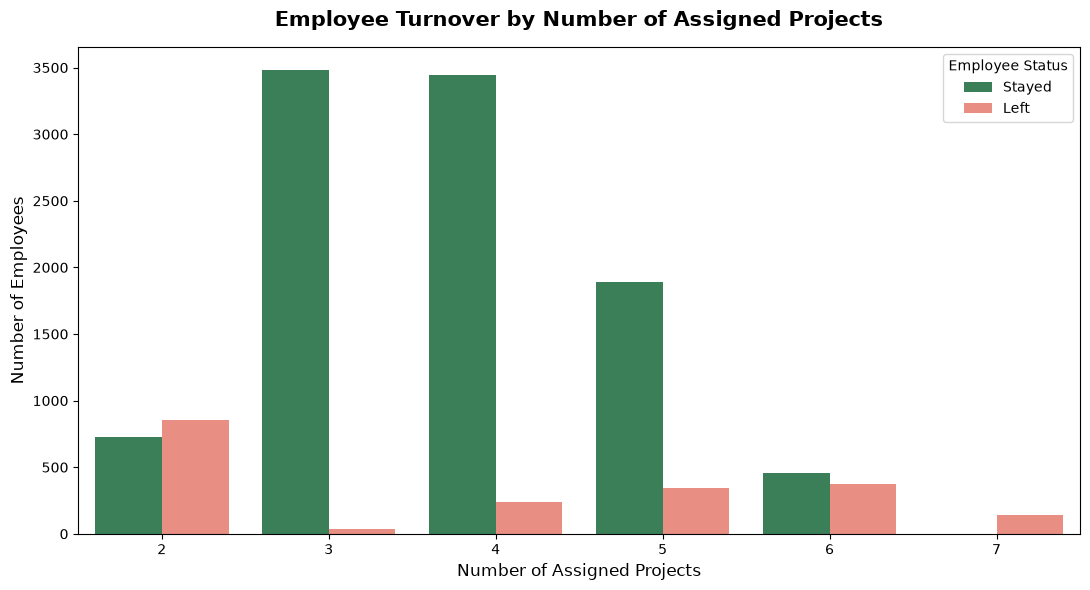

In [23]:
# Set the figure dimensions
plt.figure(figsize=(11, 6))

# Create a grouped count plot
ax = sns.countplot(
    data=df_clean,
    x="number_project",
    hue="left",
    palette={0: "seagreen", 1: "salmon"}
)

# Add a descriptive title
plt.title(
    "Employee Turnover by Number of Assigned Projects",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Add professional axis labels
plt.xlabel("Number of Assigned Projects", fontsize=12)
plt.ylabel("Number of Employees", fontsize=12)

# Improve legend labels
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles,
    ["Stayed", "Left"],
    title="Employee Status"
)

# Improve spacing
plt.tight_layout()

# Display the visualization
plt.show()

In [24]:
# Count employees by project count and turnover status
project_counts = pd.crosstab(
    df_clean["number_project"],
    df_clean["left"]
)

# Rename columns for readability
project_counts.columns = ["Stayed", "Left"]

# Display the table
project_counts

,Stayed,Left
number_project,,
2,725,857
3,3482,38
4,3448,237
5,1890,343
6,455,371
7,0,145


In [25]:
# Calculate turnover percentage for each project-count group
project_turnover_rate = (
    df_clean.groupby("number_project")["left"]
    .mean()
    .mul(100)
    .round(2)
)

# Display the turnover percentages
project_turnover_rate

number_project
2     54.17
3      1.08
4      6.43
5     15.36
6     44.92
7    100.00
Name: left, dtype: float64

#### Employee Project Count and Turnover Findings

A grouped count plot was created to examine employee
turnover across different numbers of assigned projects.

The analysis identified substantial differences in
turnover rates between project-count categories.

Employees assigned two projects demonstrated a turnover
rate of 54.17%, with 857 of 1,582 employees leaving
the organization.

Employees assigned three projects demonstrated the
lowest turnover rate at 1.08%, followed by employees
assigned four projects at 6.43%.

Turnover rates increased among employees assigned
larger numbers of projects.

Employees assigned five projects had a turnover rate
of 15.36%, while employees assigned six projects had
a turnover rate of 44.92%.

All 145 employees assigned seven projects left the
organization, producing an observed turnover rate
of 100% within that group.

These findings indicate that turnover is substantially
higher among employees assigned very few or very many
projects compared with employees assigned three or
four projects.

The relationship appears nonlinear, which helps explain
why the Pearson correlation between project count and
turnover was close to zero (r = 0.031).

Potential explanations include employee disengagement,
workload imbalances, or differences in job responsibilities.

However, these explanations remain hypotheses because
the analysis identifies associations rather than
causal relationships.

The findings suggest that project workload may be a
valuable predictor in the employee turnover models.

Further modeling will investigate whether project count
contributes predictive information when considered
alongside other employee characteristics.

## K-Means Clustering of Employees Who Left

### Objective

The objective of this analysis is to identify distinct
groups of employees who left Portobello Tech based on
their satisfaction levels and performance evaluations.

K-means clustering is an unsupervised machine learning
algorithm that groups observations according to their
similarity.

The analysis will use the following variables:

- `satisfaction_level`: Employee satisfaction score.
- `last_evaluation`: Most recent performance evaluation.
- `left`: Employee turnover status, used to select
  employees who left the organization.

The clustering algorithm will use three clusters
(K = 3), as required by the project instructions.

The resulting clusters will be analyzed to identify
patterns that may help inform employee retention
strategies.

In [26]:
# Import the K-means clustering algorithm
from sklearn.cluster import KMeans

In [27]:
# Select employees who left the organization
employees_left = df_clean[
    df_clean["left"] == 1
].copy()

# Count the employees who left
print("Employees who left:", len(employees_left))

# Preview the filtered dataset
employees_left.head()

Employees who left: 1991


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [28]:
# Select the features used for clustering
cluster_features = employees_left[
    ["satisfaction_level", "last_evaluation"]
].copy()

# Preview the selected features
cluster_features.head()

,satisfaction_level,last_evaluation
0,0.38,0.53
1,0.80,0.86
2,0.11,0.88
3,0.72,0.87
4,0.37,0.52


In [29]:
# Initialize K-means with three clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train K-means and assign cluster labels
cluster_labels = kmeans.fit_predict(cluster_features)

# Store cluster labels in the employee dataset
employees_left["cluster"] = cluster_labels

# Display the number of employees in each cluster
employees_left["cluster"].value_counts().sort_index()

cluster
0    902
1    555
2    534
Name: count, dtype: int64

In [30]:
# Create a table of cluster centers
cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["Satisfaction Level", "Evaluation Score"]
)

# Give the index a descriptive label
cluster_centers.index.name = "Cluster"

# Display results rounded to three decimal places
cluster_centers.round(3)

,Satisfaction Level,Evaluation Score
Cluster,,
0,0.410,0.517
1,0.806,0.913
2,0.111,0.869


### K-Means Cluster Visualization

A scatter plot will be created to visualize the three
clusters identified by the K-means algorithm.

Employee satisfaction will be displayed on the
horizontal axis, while performance evaluation
scores will be displayed on the vertical axis.

Each cluster will be represented by a different
color, and the cluster centroids will be marked
to illustrate the center of each group.

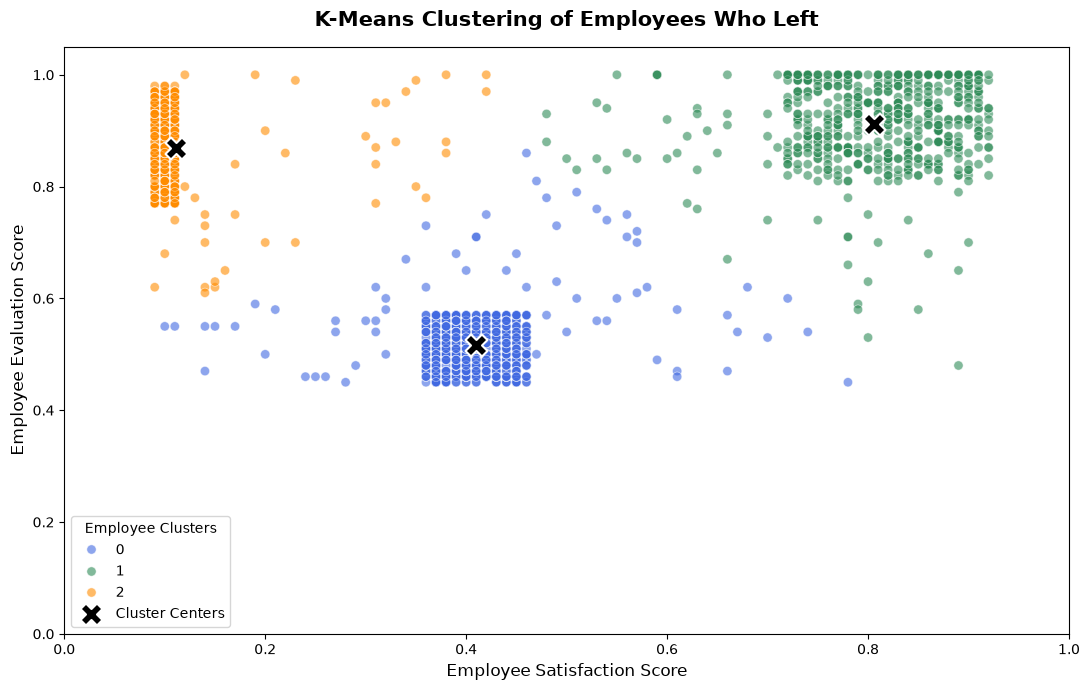

In [31]:
# Set the figure dimensions
plt.figure(figsize=(11, 7))

# Plot employees using their assigned clusters
ax = sns.scatterplot(
    data=employees_left,
    x="satisfaction_level",
    y="last_evaluation",
    hue="cluster",
    palette={
        0: "royalblue",
        1: "seagreen",
        2: "darkorange"
    },
    s=45,
    alpha=0.6
)

# Plot the cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=250,
    c="black",
    marker="X",
    edgecolors="white",
    linewidths=1.5,
    label="Cluster Centers"
)

# Add a professional title
plt.title(
    "K-Means Clustering of Employees Who Left",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Label the axes
plt.xlabel("Employee Satisfaction Score", fontsize=12)
plt.ylabel("Employee Evaluation Score", fontsize=12)

# Set axis limits
plt.xlim(0, 1)
plt.ylim(0, 1.05)

# Improve legend
plt.legend(
    title="Employee Clusters",
    loc="best"
)

# Improve spacing
plt.tight_layout()

# Display the scatter plot
plt.show()


### K-Means Clustering Findings

K-means clustering was performed on 1,991 employee records
representing employees who left Portobello Tech.

The analysis used employee satisfaction and performance
evaluation scores, with the number of clusters set to
three (K = 3).

#### Cluster 0: Lower Satisfaction and Moderate Evaluations

Cluster 0 contained 902 employees, representing
approximately 45.3% of departing employees.

The cluster centroid had a satisfaction score of 0.410
and an evaluation score of 0.517.

This was the largest cluster and represented departing
employees with relatively low satisfaction and moderate
performance evaluation scores.

#### Cluster 1: High Satisfaction and High Evaluations

Cluster 1 contained 555 employees, representing
approximately 27.9% of departing employees.

The cluster centroid had a satisfaction score of 0.806
and an evaluation score of 0.913.

This cluster demonstrated that some employees left
despite having high satisfaction and performance
evaluation scores.

#### Cluster 2: Very Low Satisfaction and High Evaluations

Cluster 2 contained 534 employees, representing
approximately 26.8% of departing employees.

The cluster centroid had a satisfaction score of 0.111
and an evaluation score of 0.869.

This cluster identified departing employees who
demonstrated strong performance evaluations but
reported very low satisfaction.

#### Business Interpretation

The clustering results identified three distinct
employee departure profiles.

The findings suggest that departing employees do not
share identical satisfaction and performance
characteristics.

Potential retention strategies may therefore need
to address different employee circumstances.

However, these clusters were generated exclusively
from employees who left the organization.

Consequently, the clusters describe differences among
departing employees but do not independently establish
which employee profiles have the highest turnover risk.

#### Conclusion

K-means clustering successfully separated the
departing employees into three groups based on
satisfaction and evaluation scores.

The results demonstrate how unsupervised machine
learning can identify employee patterns that may
support further HR investigation.

Additional supervised classification modeling is
required to predict employee turnover among the
broader workforce.



## Data Preprocessing for Classification

### Objective

The objective of this stage is to prepare the employee
dataset for supervised machine learning classification.

The target variable is `left`, where:

- 0 indicates that an employee stayed.
- 1 indicates that an employee left.

The dataset contains both numerical and categorical
features.

Categorical variables must be converted into numerical
representations before training classification models.

One-hot encoding will be performed using the Pandas
`get_dummies()` function.

After feature preparation, the dataset will be divided
into stratified training and testing sets using an
80:20 split with a random state of 123.

Class imbalance will then be addressed using SMOTE.


In [32]:
# Separate the independent variables (features)
X = df_clean.drop(columns=["left"])

# Separate the dependent variable (target)
y = df_clean["left"]

# Verify dimensions
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature dataset shape: (11991, 9)
Target dataset shape: (11991,)


In [33]:
# Select numerical features
numeric_features = X.select_dtypes(
    include=["number"]
)

# Select categorical features
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
)

# Display the column names
print("Numerical Features:")
print(numeric_features.columns.tolist())

print("\nCategorical Features:")
print(categorical_features.columns.tolist())

# Display their dimensions
print("\nNumerical shape:", numeric_features.shape)
print("Categorical shape:", categorical_features.shape)

Numerical Features:
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years']

Categorical Features:
['sales', 'salary']

Numerical shape: (11991, 7)
Categorical shape: (11991, 2)


In [34]:
# Convert categorical variables into numerical indicators
categorical_encoded = pd.get_dummies(
    categorical_features,
    dtype=int
)

# Display the first five rows
categorical_encoded.head()

,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0,0,0,0,0,0,0,1,0,0,0,1,0


In [35]:
# Combine numerical and encoded categorical variables
X_encoded = pd.concat(
    [numeric_features, categorical_encoded],
    axis=1
)

# Verify the resulting feature matrix
print("Encoded feature shape:", X_encoded.shape)

# Check for missing values
print("Missing values:", X_encoded.isnull().sum().sum())

# Display the encoded features
X_encoded.head()

Encoded feature shape: (11991, 20)
Missing values: 0


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0


In [36]:
# Verify encoded dataset dimensions
print("Encoded dataset shape:", X_encoded.shape)

# Check for missing values
print("Missing values:", X_encoded.isnull().sum().sum())

# Confirm all features are numerical
print(
    "All columns numerical:",
    all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_encoded.dtypes)
)

# Confirm no target variable was included
print("Target excluded:", "left" not in X_encoded.columns)

Encoded dataset shape: (11991, 20)
Missing values: 0
All columns numerical: True
Target excluded: True



### Categorical Feature Encoding Findings

The employee dataset was prepared for supervised
machine learning by separating the independent
variables from the target variable.

The target variable, `left`, was stored separately
from the predictor features to prevent target leakage.

The original feature dataset contained nine variables,
consisting of seven numerical variables and two
categorical variables.

The categorical variables were:

- `sales`: Employee department
- `salary`: Employee salary category

One-hot encoding was applied using the Pandas
`get_dummies()` function.

The department variable was expanded into ten binary
indicator columns, while the salary variable was
expanded into three binary indicator columns.

The encoded categorical variables were combined with
the seven original numerical predictors.

The resulting feature matrix contained 20 numerical
columns representing 11,991 employee records.

One-hot encoding allows categorical information to be
used by machine learning algorithms without assigning
arbitrary numerical distances between categories.

The encoded features will be used to prepare the
training and testing datasets.

Categorical indicators are created with `get_dummies()` before the split, as specified by the assignment. This establishes the category vocabulary using the full dataset; categorical encoding is not fitted inside the pipelines. For deployment, learn the vocabulary on training data and handle unknown categories explicitly.

All three modeling pipelines fit numerical scaling and SMOTE within each training fold. Scaling before SMOTE prevents monthly hours from dominating its distance calculations. One-hot indicators pass through unchanged. Standard SMOTE can still interpolate categorical indicators; this remains a limitation of the required approach.


In [37]:
# Import the train/test splitting function
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    stratify=y,
    random_state=123
)

# Display the resulting dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (9592, 20)
Testing features: (2399, 20)
Training labels: (9592,)
Testing labels: (2399,)


In [38]:
# Compare employee turnover percentages

print("Original Class Distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Original Class Distribution:
left
0    83.4
1    16.6
Name: proportion, dtype: float64

Training Class Distribution:
left
0    83.39
1    16.61
Name: proportion, dtype: float64

Testing Class Distribution:
left
0    83.41
1    16.59
Name: proportion, dtype: float64



### Stratified Train/Test Split Findings

The encoded employee dataset contained 11,991 observations
and 20 numerical predictor features.

The dataset was divided into training and testing subsets
using an 80:20 stratified split with random_state=123.

The resulting datasets contained:

- Training features: 9,592 observations and 20 columns
- Testing features: 2,399 observations and 20 columns
- Training labels: 9,592 observations
- Testing labels: 2,399 observations

Stratification preserved the employee turnover distribution.

The original dataset contained approximately 83.40%
employees who stayed and 16.60% who left.

The training dataset contained 83.39% employees who
stayed and 16.61% who left.

The testing dataset contained 83.41% employees who
stayed and 16.59% who left.

These results confirm that the class proportions were
successfully preserved during the split.

The training dataset will be used for model development
and class balancing.

The testing dataset will remain separate and will be
used to evaluate model performance on unseen records.


In [39]:
# Import SMOTE from the imbalanced-learn library
from imblearn.over_sampling import SMOTE

In [40]:
# Count employees in each training class
print("Training class counts before SMOTE:")
print(y_train.value_counts())

# Calculate class percentages
print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Training class counts before SMOTE:
left
0    7999
1    1593
Name: count, dtype: int64

Training class percentages:
left
0    83.39
1    16.61
Name: proportion, dtype: float64


In [41]:
from imblearn.over_sampling import SMOTE

In [42]:
# Initialize SMOTE
smote = SMOTE(
    sampling_strategy="auto",
    random_state=123
)

# Apply SMOTE only to the training dataset
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# Display class distribution after SMOTE
print("Training class counts after SMOTE:")
print(y_train_smote.value_counts())

# Display new dataset dimensions
print("\nOriginal training shape:", X_train.shape)
print("SMOTE training shape:", X_train_smote.shape)

Training class counts after SMOTE:
left
0    7999
1    7999
Name: count, dtype: int64

Original training shape: (9592, 20)
SMOTE training shape: (15998, 20)


In [43]:
# Confirm the test dataset has not been resampled
print("Test feature shape:", X_test.shape)
print("Test label shape:", y_test.shape)

print("\nTest class distribution:")
print(y_test.value_counts())

Test feature shape: (2399, 20)
Test label shape: (2399,)

Test class distribution:
left
0    2001
1     398
Name: count, dtype: int64



### SMOTE Class Balancing Findings

The training dataset initially contained 9,592 employee
records and 20 numerical predictor features.

The class distribution was imbalanced:

- Employees who stayed: 7,999 (83.39%)
- Employees who left: 1,593 (16.61%)

The Synthetic Minority Over-sampling Technique (SMOTE)
was applied to address the underrepresentation of
employees who left the organization.

SMOTE was configured with a random state of 123 and
the default automatic sampling strategy.

After applying SMOTE, the training dataset contained
15,998 observations:

- Employees who stayed: 7,999 (50%)
- Employees who left: 7,999 (50%)

The algorithm generated 6,406 synthetic minority-class
observations while retaining the original majority
class count.

The number of predictor features remained unchanged
at 20.

The held-out testing dataset was not modified and
continued to contain 2,399 observations:

- Employees who stayed: 2,001
- Employees who left: 398

Maintaining the original test distribution is important
for evaluating model performance on representative
unseen observations.

Standard SMOTE may generate fractional values in
one-hot encoded categorical features. This limitation
will be considered when interpreting model results.

During five-fold cross-validation, SMOTE will be
performed separately within each training fold using
an imbalanced-learn pipeline to prevent resampling
leakage into validation folds.

The balanced dataset created in this section serves
as a demonstration of the resampling process.



## Logistic Regression Classification

### Objective

The objective of this analysis is to train a Logistic
Regression classifier to predict employee turnover.

The target variable is `left`, where:

- 0 indicates an employee stayed.
- 1 indicates an employee left.

Logistic Regression is a supervised machine learning
algorithm used for binary classification.

The model estimates the probability that an employee
belongs to the positive class.

The model will be evaluated using five-fold
cross-validation, as required by the project.

A machine learning pipeline will be used to apply
feature scaling and SMOTE within each training fold,
preventing preprocessing and resampling leakage.

The evaluation will consider precision, recall,
F1-score, and classification performance.


In [44]:
# Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Column-specific preprocessing
from sklearn.compose import ColumnTransformer

# Pipeline supporting SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from IPython.display import Markdown, display as display_markdown


In [45]:
# Scale only the seven original numerical predictors
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric_scaler",
            StandardScaler(),
            numeric_features.columns.tolist()
        )
    ],
    remainder="passthrough"
)

# Create the classification pipeline
logistic_pipeline = ImbPipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("smote", SMOTE(random_state=123)),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=123
            )
        )
    ]
)

# Display the pipeline
logistic_pipeline

,steps,"[('preprocessing', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric_scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for fo

In [46]:
# Configure stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

print("Cross-validation configured successfully.")
print("Number of folds:", cv.get_n_splits())

Cross-validation configured successfully.
Number of folds: 5



### Five-Fold Cross-Validation

The Logistic Regression model will be evaluated using
five-fold stratified cross-validation.

During each fold, the preprocessing pipeline will
standardize numerical features and apply SMOTE only
to the training portion of the fold.

Performance will be evaluated using accuracy,
precision, recall, F1-score, and ROC-AUC.

Recall and precision for the employee turnover class
(left = 1) will receive particular attention.


In [47]:
# Define our evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Run five-fold cross-validation
logistic_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display average performance and variation across folds
for metric in scoring:
    scores = logistic_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"Mean = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

ACCURACY  : Mean = 0.7761, Std = 0.0088
PRECISION : Mean = 0.4132, Std = 0.0111
RECALL    : Mean = 0.8261, Std = 0.0214
F1        : Mean = 0.5507, Std = 0.0113
ROC_AUC   : Mean = 0.8410, Std = 0.0053


In [48]:
# Create a DataFrame of cross-validation scores
logistic_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": logistic_cv_results["test_accuracy"],
    "Precision": logistic_cv_results["test_precision"],
    "Recall": logistic_cv_results["test_recall"],
    "F1 Score": logistic_cv_results["test_f1"],
    "ROC-AUC": logistic_cv_results["test_roc_auc"]
})

# Display the results
logistic_cv_df.round(4)

,Fold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1,0.7645,0.4000,0.8339,0.5407,0.8444
1,2,0.7728,0.4120,0.8589,0.5569,0.8455
2,3,0.7706,0.4026,0.7925,0.5339,0.8309
3,4,0.7847,0.4233,0.8239,0.5592,0.8409
4,5,0.7878,0.4281,0.8213,0.5628,0.8434


### Cross-validation of tree models and model selection

All candidates are compared on training folds before evaluating the held-out test set. Scaling precedes SMOTE in every pipeline.

In [49]:
# Import the Random Forest classification algorithm
from sklearn.ensemble import RandomForestClassifier

In [50]:
# Create the Random Forest pipeline
random_forest_pipeline = ImbPipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("smote", SMOTE(random_state=123)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=123,
                n_jobs=-1
            )
        )
    ]
)

# Display the pipeline
random_forest_pipeline

,steps,"[('preprocessing', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric_scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for fo

In [51]:
# Run five-fold cross-validation
random_forest_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# Display mean and standard deviation
for metric in scoring:
    scores = random_forest_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"Mean = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

ACCURACY  : Mean = 0.9818, Std = 0.0011
PRECISION : Mean = 0.9780, Std = 0.0118
RECALL    : Mean = 0.9109, Std = 0.0066
F1        : Mean = 0.9431, Std = 0.0032
ROC_AUC   : Mean = 0.9828, Std = 0.0052


In [52]:
# Organize cross-validation results into a table
random_forest_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": random_forest_cv_results["test_accuracy"],
    "Precision": random_forest_cv_results["test_precision"],
    "Recall": random_forest_cv_results["test_recall"],
    "F1 Score": random_forest_cv_results["test_f1"],
    "ROC-AUC": random_forest_cv_results["test_roc_auc"]
})

# Display results
random_forest_cv_df.round(4)

,Fold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1,0.9802,0.9607,0.9185,0.9391,0.9845
1,2,0.9833,0.9832,0.9154,0.9481,0.9870
2,3,0.9828,0.9965,0.8994,0.9455,0.9735
3,4,0.9812,0.9764,0.9088,0.9414,0.9881
4,5,0.9812,0.9732,0.9122,0.9417,0.9811


In [53]:
# Import Gradient Boosting classifier
from sklearn.ensemble import GradientBoostingClassifier

In [54]:
# Create the Gradient Boosting pipeline
gradient_boosting_pipeline = ImbPipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("smote", SMOTE(random_state=123)),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=200,
                learning_rate=0.1,
                max_depth=3,
                random_state=123
            )
        )
    ]
)

# Display the pipeline
gradient_boosting_pipeline

,steps,"[('preprocessing', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric_scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for fo

In [55]:
# Run five-fold cross-validation
gradient_boosting_cv_results = cross_validate(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# Display mean and standard deviation
for metric in scoring:
    scores = gradient_boosting_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"Mean = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

ACCURACY  : Mean = 0.9781, Std = 0.0013
PRECISION : Mean = 0.9376, Std = 0.0108
RECALL    : Mean = 0.9303, Std = 0.0097
F1        : Mean = 0.9338, Std = 0.0038
ROC_AUC   : Mean = 0.9866, Std = 0.0033


In [56]:
# Organize cross-validation results into a DataFrame
gradient_boosting_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": gradient_boosting_cv_results["test_accuracy"],
    "Precision": gradient_boosting_cv_results["test_precision"],
    "Recall": gradient_boosting_cv_results["test_recall"],
    "F1 Score": gradient_boosting_cv_results["test_f1"],
    "ROC-AUC": gradient_boosting_cv_results["test_roc_auc"]
})

# Display the cross-validation table
gradient_boosting_cv_df.round(4)

,Fold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1,0.9792,0.9319,0.9436,0.9377,0.9869
1,2,0.9781,0.9342,0.9342,0.9342,0.9898
2,3,0.9776,0.9479,0.9151,0.9312,0.9803
3,4,0.9760,0.9224,0.9340,0.9281,0.9880
4,5,0.9797,0.9516,0.9248,0.9380,0.9879


In [57]:
# Select using training cross-validation only, before test evaluation.
cv_results_by_model = {
    "Logistic Regression": logistic_cv_results,
    "Random Forest": random_forest_cv_results,
    "Gradient Boosting": gradient_boosting_cv_results,
}
cv_comparison_df = pd.DataFrame([
    {"Model": name, **{metric: results[f"test_{metric}"].mean()
                       for metric in scoring}}
    for name, results in cv_results_by_model.items()
])
# Recall is primary; ROC-AUC and precision break exact ties.
model_ranking_df = cv_comparison_df.sort_values(
    ["recall", "roc_auc", "precision"], ascending=False
).reset_index(drop=True)
best_model_name = model_ranking_df.loc[0, "Model"]
print("Selected by training CV:", best_model_name)
model_ranking_df.round(4)


Selected by training CV: Gradient Boosting


,Model,accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.9781,0.9376,0.9303,0.9338,0.9866
1,Random Forest,0.9818,0.9780,0.9109,0.9431,0.9828
2,Logistic Regression,0.7761,0.4132,0.8261,0.5507,0.8410


### Logistic Regression Test Set Evaluation

After five-fold cross-validation, the Logistic
Regression pipeline is fitted using the full
training dataset.

The fitted model is then evaluated on the original
held-out test dataset.

A classification report will be generated to
examine precision, recall, F1-score, and support
for each employee turnover class.

In [58]:
# Fit the full pipeline using the original training set
logistic_pipeline.fit(X_train, y_train)

# Generate predictions on the untouched test dataset
y_pred_logistic = logistic_pipeline.predict(X_test)

print("Logistic Regression model trained successfully.")
print("Test predictions generated:", len(y_pred_logistic))

Logistic Regression model trained successfully.
Test predictions generated: 2399


In [59]:
# Import classification evaluation tools
from sklearn.metrics import classification_report

# Generate classification report
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=["Stayed", "Left"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Stayed     0.9550    0.7636    0.8487      2001
        Left     0.4080    0.8191    0.5447       398

    accuracy                         0.7728      2399
   macro avg     0.6815    0.7914    0.6967      2399
weighted avg     0.8643    0.7728    0.7982      2399




### Logistic Regression Confusion Matrix

A confusion matrix will be used to evaluate the
number of correct and incorrect predictions made
by the Logistic Regression classifier.

The matrix will identify:

- True Negatives: Employees correctly predicted to stay
- False Positives: Employees incorrectly predicted to leave
- False Negatives: Employees incorrectly predicted to stay
- True Positives: Employees correctly predicted to leave

The results will help assess the tradeoff between
identifying departing employees and generating
false-positive predictions.


In [60]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

# Display the numerical results
print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

# Extract individual counts
tn, fp, fn, tp = cm_logistic.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Logistic Regression Confusion Matrix:
[[1528  473]
 [  72  326]]

True Negatives: 1528
False Positives: 473
False Negatives: 72
True Positives: 326


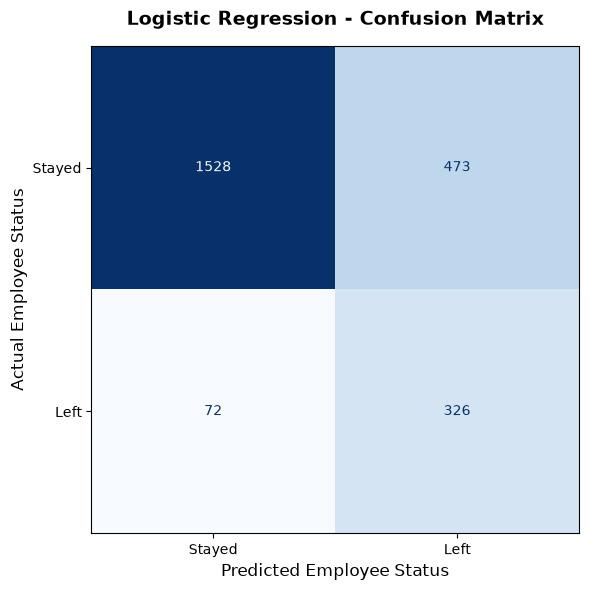

In [61]:
# Create the figure
fig, ax = plt.subplots(figsize=(8, 6))

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Stayed", "Left"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

# Add a descriptive title
ax.set_title(
    "Logistic Regression - Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Employee Status", fontsize=12)
ax.set_ylabel("Actual Employee Status", fontsize=12)

plt.tight_layout()
plt.show()


### Logistic Regression Confusion Matrix Findings

The Logistic Regression model was evaluated on
2,399 previously unseen employee observations.

The confusion matrix produced the following results:

- True Negatives (TN): 1,528
- False Positives (FP): 473
- False Negatives (FN): 72
- True Positives (TP): 326

#### Interpretation

The model correctly identified 326 of the 398 employees
who actually left the company.

This corresponds to a turnover recall of 81.91%.

However, 72 departing employees were incorrectly
predicted to stay, representing a false negative
rate of approximately 18.09%.

Among the 2,001 employees who stayed, 473 were
incorrectly predicted to leave.

This represents a false positive rate of approximately
23.64%.

#### Business Implications

The model demonstrates relatively strong sensitivity
for identifying employees who may leave.

However, its relatively high false positive rate may
lead to unnecessary retention interventions and
inefficient allocation of HR resources.

The model's classification threshold may need to be
adjusted depending on the organization's priorities
and the relative costs of missed departures and
false alarms.

Overall, Logistic Regression provides a useful
baseline for comparison with more complex models.



### Logistic Regression ROC-AUC Evaluation

The Receiver Operating Characteristic (ROC) curve
evaluates the Logistic Regression model's ability
to distinguish between employees who stayed and
employees who left across different classification
thresholds.

The ROC curve plots the True Positive Rate (Recall)
against the False Positive Rate.

The Area Under the Curve (AUC) summarizes the model's
overall ability to distinguish between the two classes.

Predicted probabilities from the held-out test dataset
will be used to calculate ROC-AUC and generate the
ROC curve.

The results will be compared against the five-fold
cross-validation ROC-AUC score of 0.8410.


In [62]:
# Generate probabilities for the employee turnover class
y_prob_logistic = logistic_pipeline.predict_proba(X_test)[:, 1]

# Display the first 10 predicted probabilities
print("Predicted turnover probabilities:")
print(y_prob_logistic[:10])

Predicted turnover probabilities:
[0.37620416 0.86219324 0.1931226  0.26905422 0.55975266 0.62234269
 0.95684482 0.46997324 0.01550264 0.15648459]


In [63]:
# Import ROC evaluation tools
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate false positive and true positive rates
fpr_logistic, tpr_logistic, thresholds_logistic = roc_curve(
    y_test,
    y_prob_logistic
)

# Calculate the area under the ROC curve
auc_logistic = roc_auc_score(
    y_test,
    y_prob_logistic
)

# Display the test ROC-AUC
print(f"Logistic Regression Test ROC-AUC: {auc_logistic:.4f}")

Logistic Regression Test ROC-AUC: 0.8326


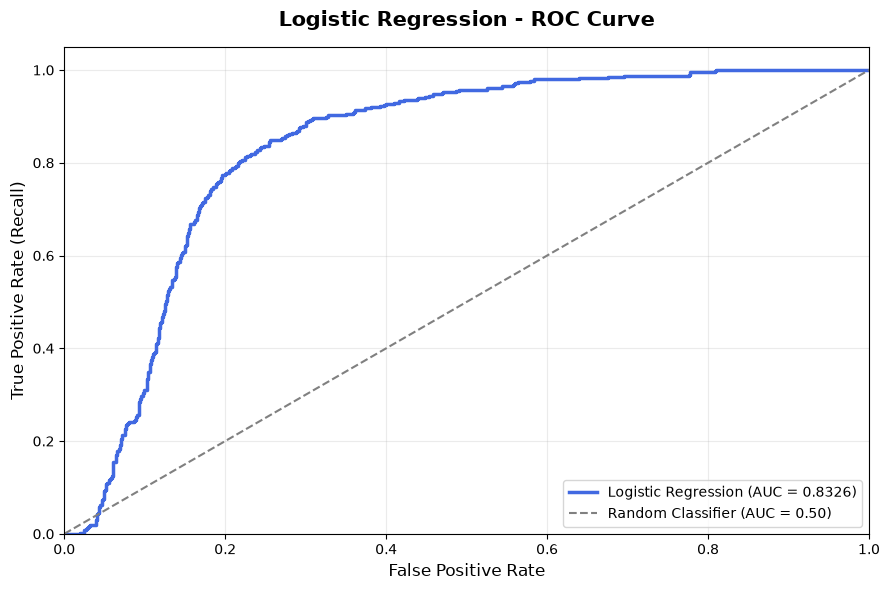

In [64]:
# Create the visualization
plt.figure(figsize=(9, 6))

# Plot the Logistic Regression ROC curve
plt.plot(
    fpr_logistic,
    tpr_logistic,
    color="royalblue",
    linewidth=2.5,
    label=f"Logistic Regression (AUC = {auc_logistic:.4f})"
)

# Add the random-classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

# Format the visualization
plt.title(
    "Logistic Regression - ROC Curve",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


### Logistic Regression ROC-AUC Findings

The Logistic Regression model was evaluated using
predicted turnover probabilities from the held-out
test dataset.

The Receiver Operating Characteristic (ROC) curve
was generated by plotting the True Positive Rate
against the False Positive Rate across different
classification thresholds.

#### Results

- Five-fold cross-validation ROC-AUC: 0.8410
- Test dataset ROC-AUC: 0.8326
- Difference: 0.0084

#### Interpretation

The ROC curve remained above the diagonal random
classifier baseline, indicating that the model
distinguishes departing employees from employees
who stayed better than chance-level ranking.

The test ROC-AUC of 0.8326 demonstrates reasonably
strong discrimination between the two employee
classes.

The small difference between the cross-validation
and test ROC-AUC scores suggests that model
discrimination remained relatively consistent
on previously unseen data.

However, ROC-AUC alone does not establish whether
the model's predicted probabilities are calibrated
or whether the default classification threshold
is appropriate for the business objective.

#### Conclusion

Logistic Regression provides a useful baseline
classification model for predicting employee turnover.

The model demonstrated relatively high recall for
departing employees but comparatively low precision.

Its performance will be compared with Random Forest
and Gradient Boosting classifiers to determine
which model provides the most appropriate balance
of recall, precision, F1-score, and ROC-AUC.



## Random Forest Classification

### Objective

The objective of this analysis is to train and evaluate
a Random Forest Classifier to predict employee turnover.

Random Forest is an ensemble learning algorithm that
combines predictions from multiple decision trees.

Unlike Logistic Regression, Random Forest can capture
nonlinear relationships and interactions between
employee characteristics.

The classifier will be evaluated using five-fold
stratified cross-validation.

SMOTE will be applied separately within each training
fold to address class imbalance without introducing
resampling leakage into validation data.

The results will be compared against Logistic Regression
using accuracy, precision, recall, F1-score, and ROC-AUC.



### Random Forest Test Set Evaluation

Following five-fold cross-validation, the Random Forest
pipeline will be fitted on the full training dataset.

The trained classifier will generate predictions for
the held-out test dataset containing 2,399 employees.

A classification report will be used to examine
precision, recall, F1-score, and accuracy.

The results will be compared against Logistic
Regression to assess improvements in employee
turnover prediction.


In [65]:
# Train Random Forest using the original training data
random_forest_pipeline.fit(X_train, y_train)

# Generate predictions on the untouched test dataset
y_pred_forest = random_forest_pipeline.predict(X_test)

# Verify the number of predictions
print("Random Forest trained successfully.")
print("Test predictions generated:", len(y_pred_forest))

Random Forest trained successfully.
Test predictions generated: 2399


In [66]:
# Generate the Random Forest classification report
print(
    classification_report(
        y_test,
        y_pred_forest,
        target_names=["Stayed", "Left"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Stayed     0.9808    0.9950    0.9878      2001
        Left     0.9729    0.9020    0.9361       398

    accuracy                         0.9796      2399
   macro avg     0.9768    0.9485    0.9620      2399
weighted avg     0.9795    0.9796    0.9793      2399




### Random Forest Confusion Matrix

The confusion matrix will evaluate the number of
correct and incorrect employee turnover predictions
made by the Random Forest classifier.

The analysis will examine true positives, true
negatives, false positives, and false negatives.

Particular attention will be given to false negatives,
which represent departing employees that the model
failed to identify.

The results will be compared against Logistic Regression
to assess improvements in employee turnover detection.


In [67]:
# Calculate Random Forest confusion matrix
cm_forest = confusion_matrix(
    y_test,
    y_pred_forest
)

# Display the numerical matrix
print("Random Forest Confusion Matrix:")
print(cm_forest)

# Extract confusion matrix values
tn_forest, fp_forest, fn_forest, tp_forest = cm_forest.ravel()

print("\nTrue Negatives:", tn_forest)
print("False Positives:", fp_forest)
print("False Negatives:", fn_forest)
print("True Positives:", tp_forest)

Random Forest Confusion Matrix:
[[1991   10]
 [  39  359]]

True Negatives: 1991
False Positives: 10
False Negatives: 39
True Positives: 359


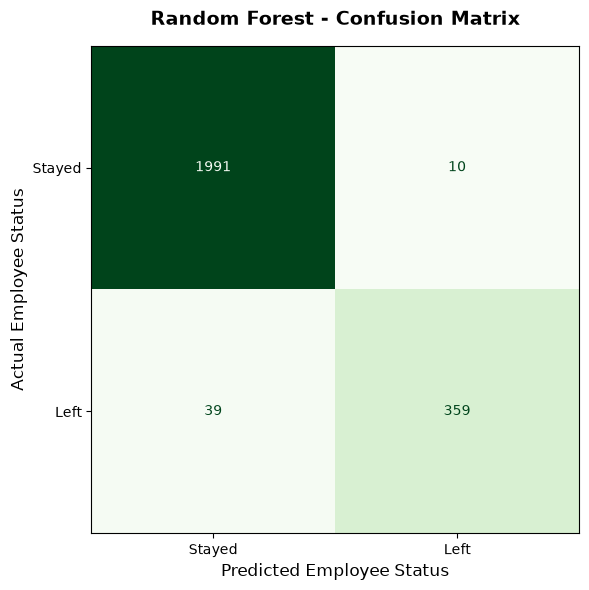

In [68]:
# Create the figure
fig, ax = plt.subplots(figsize=(8, 6))

# Display Random Forest confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_forest,
    display_labels=["Stayed", "Left"]
)

display.plot(
    ax=ax,
    cmap="Greens",
    values_format="d",
    colorbar=False
)

# Format the visualization
ax.set_title(
    "Random Forest - Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Employee Status", fontsize=12)
ax.set_ylabel("Actual Employee Status", fontsize=12)

plt.tight_layout()
plt.show()


### Random Forest ROC-AUC Evaluation

The Receiver Operating Characteristic (ROC) curve
will be used to evaluate the Random Forest model's
ability to distinguish employees who stayed from
employees who left across classification thresholds.

Predicted probabilities from the held-out test
dataset will be used to calculate the ROC curve
and Area Under the Curve (AUC).

The resulting test ROC-AUC will be compared against
the updated five-fold cross-validation ROC-AUC
and the Logistic Regression test ROC-AUC of 0.8326.


In [69]:
# Generate predicted probabilities for employee turnover
y_prob_forest = random_forest_pipeline.predict_proba(X_test)[:, 1]

# Display the first ten probabilities
print("Random Forest turnover probabilities:")
print(y_prob_forest[:10])

Random Forest turnover probabilities:
[0.245 0.13  0.015 0.96  0.015 0.99  0.025 0.005 0.035 0.02 ]


In [70]:
# Calculate ROC curve values
fpr_forest, tpr_forest, thresholds_forest = roc_curve(
    y_test,
    y_prob_forest
)

# Calculate ROC-AUC on the test dataset
auc_forest = roc_auc_score(
    y_test,
    y_prob_forest
)

print(f"Random Forest Test ROC-AUC: {auc_forest:.4f}")

Random Forest Test ROC-AUC: 0.9717


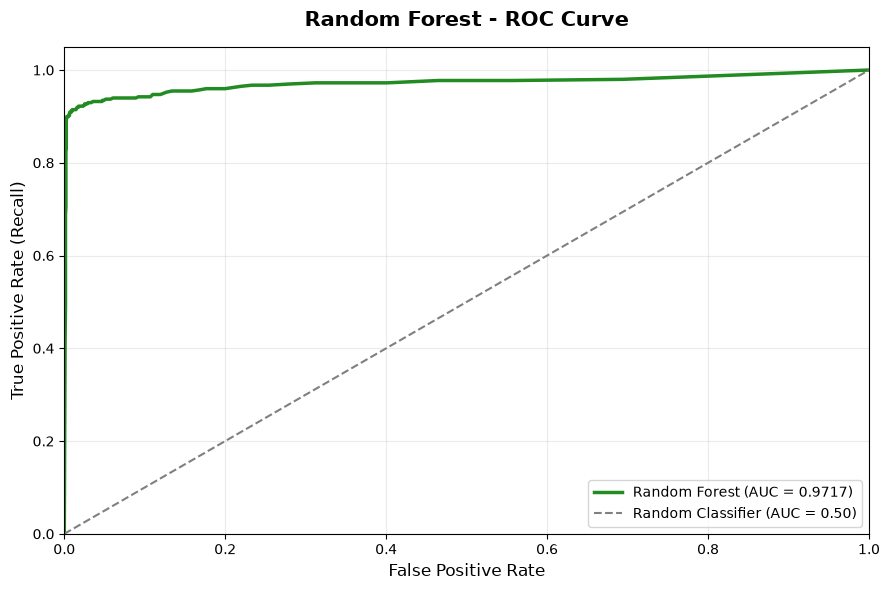

In [71]:
# Create ROC visualization
plt.figure(figsize=(9, 6))

# Plot Random Forest ROC curve
plt.plot(
    fpr_forest,
    tpr_forest,
    color="forestgreen",
    linewidth=2.5,
    label=f"Random Forest (AUC = {auc_forest:.4f})"
)

# Add random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

# Format the chart
plt.title(
    "Random Forest - ROC Curve",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Random Forest interpretation

Updated numerical findings are generated in the consolidated evaluation section below.


## Gradient Boosting Classification

### Objective

The objective of this analysis is to train and evaluate
a Gradient Boosting Classifier to predict employee
turnover at Portobello Tech.

Gradient Boosting is an ensemble learning technique
that builds decision trees sequentially to improve
the predictions of the existing model.

Unlike Random Forest, which combines independently
trained trees, Gradient Boosting progressively
minimizes prediction errors through a gradient-based
optimization process.

The classifier will be evaluated using five-fold
stratified cross-validation.

SMOTE will be applied within each training fold to
address class imbalance and prevent resampling
leakage.

Performance will be evaluated using accuracy,
precision, recall, F1-score, and ROC-AUC.

The results will be compared against Logistic
Regression and Random Forest.



### Gradient Boosting Test Set Evaluation

After completing five-fold stratified cross-validation,
the Gradient Boosting classifier will be fitted using
the full training dataset.

The trained model will be evaluated on the independent
test dataset containing 2,399 employee observations.

A classification report will be generated to examine
accuracy, precision, recall, and F1-score.

The test results will be compared with the
cross-validation results and the performance of
Logistic Regression and Random Forest.

The objective is to determine whether Gradient
Boosting maintains strong performance on previously
unseen employee records.


In [72]:
# Train Gradient Boosting using the original training set
gradient_boosting_pipeline.fit(X_train, y_train)

# Generate predictions on the independent test dataset
y_pred_gradient = gradient_boosting_pipeline.predict(X_test)

# Verify the number of predictions
print("Gradient Boosting trained successfully.")
print("Test predictions generated:", len(y_pred_gradient))

Gradient Boosting trained successfully.
Test predictions generated: 2399


In [73]:
# Generate the Gradient Boosting classification report
print(
    classification_report(
        y_test,
        y_pred_gradient,
        target_names=["Stayed", "Left"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Stayed     0.9836    0.9865    0.9850      2001
        Left     0.9311    0.9171    0.9241       398

    accuracy                         0.9750      2399
   macro avg     0.9573    0.9518    0.9545      2399
weighted avg     0.9749    0.9750    0.9749      2399




### Gradient Boosting Confusion Matrix

A confusion matrix will be used to evaluate the
classification performance of the Gradient Boosting
model on the held-out test dataset.

The matrix will identify true positives, true
negatives, false positives, and false negatives.

Particular attention will be given to the number
of departing employees correctly identified and
the number of false-positive predictions.

The results will be compared with Random Forest
and Logistic Regression to assess differences
in classification performance.


In [74]:
# Calculate Gradient Boosting confusion matrix
cm_gradient = confusion_matrix(
    y_test,
    y_pred_gradient
)

# Display confusion matrix
print("Gradient Boosting Confusion Matrix:")
print(cm_gradient)

# Extract individual values
tn_gradient, fp_gradient, fn_gradient, tp_gradient = cm_gradient.ravel()

print("\nTrue Negatives:", tn_gradient)
print("False Positives:", fp_gradient)
print("False Negatives:", fn_gradient)
print("True Positives:", tp_gradient)

Gradient Boosting Confusion Matrix:
[[1974   27]
 [  33  365]]

True Negatives: 1974
False Positives: 27
False Negatives: 33
True Positives: 365


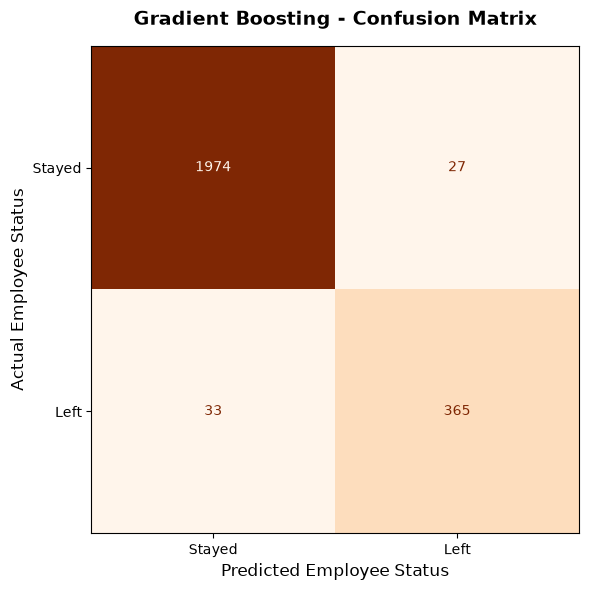

In [75]:
# Create figure
fig, ax = plt.subplots(figsize=(8, 6))

# Display Gradient Boosting confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_gradient,
    display_labels=["Stayed", "Left"]
)

display.plot(
    ax=ax,
    cmap="Oranges",
    values_format="d",
    colorbar=False
)

# Format chart
ax.set_title(
    "Gradient Boosting - Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Employee Status", fontsize=12)
ax.set_ylabel("Actual Employee Status", fontsize=12)

plt.tight_layout()
plt.show()


### Gradient Boosting ROC-AUC Evaluation

The Receiver Operating Characteristic (ROC) curve
will be used to evaluate the Gradient Boosting
classifier's ability to distinguish employees who
stayed from employees who left.

The ROC curve plots the True Positive Rate against
the False Positive Rate across classification
thresholds.

Predicted probabilities from the held-out test
dataset will be used to calculate ROC-AUC.

The resulting score will be compared against
Logistic Regression and Random Forest to assess
overall classification discrimination.


In [76]:
# Generate predicted turnover probabilities
y_prob_gradient = gradient_boosting_pipeline.predict_proba(
    X_test
)[:, 1]

# Display the first ten probabilities
print("Gradient Boosting turnover probabilities:")
print(y_prob_gradient[:10])

Gradient Boosting turnover probabilities:
[0.29479791 0.22797702 0.01450411 0.92747665 0.02277842 0.96762191
 0.09586357 0.01697096 0.00276356 0.01291282]


In [77]:
# Calculate ROC curve coordinates
fpr_gradient, tpr_gradient, thresholds_gradient = roc_curve(
    y_test,
    y_prob_gradient
)

# Calculate test ROC-AUC
auc_gradient = roc_auc_score(
    y_test,
    y_prob_gradient
)

print(f"Gradient Boosting Test ROC-AUC: {auc_gradient:.4f}")

Gradient Boosting Test ROC-AUC: 0.9786


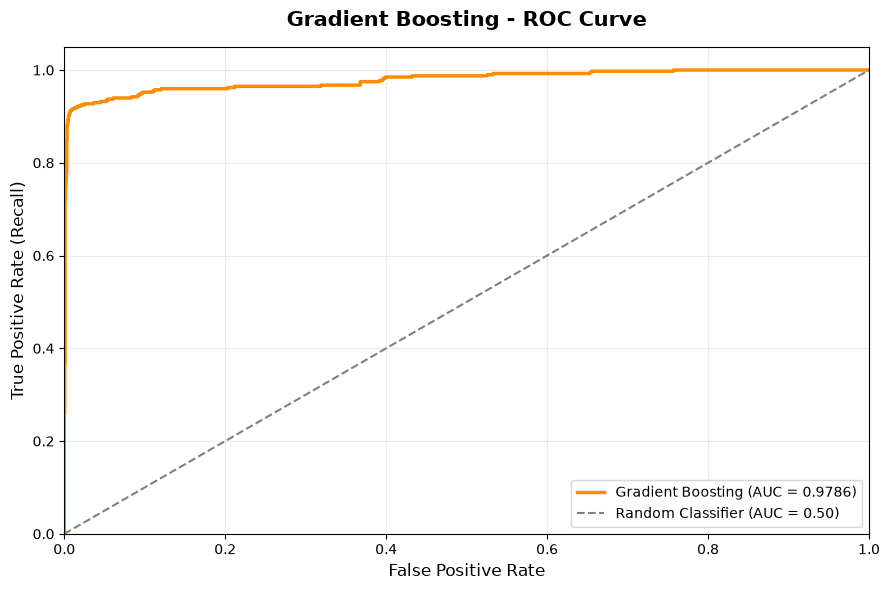

In [78]:
# Create the ROC visualization
plt.figure(figsize=(9, 6))

# Plot Gradient Boosting ROC curve
plt.plot(
    fpr_gradient,
    tpr_gradient,
    color="darkorange",
    linewidth=2.5,
    label=f"Gradient Boosting (AUC = {auc_gradient:.4f})"
)

# Plot random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.50)"
)

# Format the plot
plt.title(
    "Gradient Boosting - ROC Curve",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Gradient Boosting interpretation

Updated numerical findings are generated in the consolidated evaluation section below.

## Model Comparison and Selection

The model was selected by mean five-fold training-CV recall before test evaluation, with ROC-AUC and precision used as tie-breakers. The tables and ROC curves below report held-out performance rather than determine the winner.

Recall is prioritized because false negatives miss opportunities for retention support. Precision also matters because false positives consume HR resources and can prompt unnecessary interventions.

**Evaluation limitation:** Earlier versions of this project used this same test set for model comparison and selection. The revised code uses training CV, but this does not undo prior exposure to test results. These test scores are exploratory holdout results; a new untouched dataset is needed for a fully independent final assessment.


In [79]:
# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store each model's predictions and probabilities
model_results = {
    "Logistic Regression": {
        "predictions": y_pred_logistic,
        "probabilities": y_prob_logistic
    },
    "Random Forest": {
        "predictions": y_pred_forest,
        "probabilities": y_prob_forest
    },
    "Gradient Boosting": {
        "predictions": y_pred_gradient,
        "probabilities": y_prob_gradient
    }
}

# Calculate evaluation metrics for each model
comparison_results = []

for model_name, results in model_results.items():

    y_pred = results["predictions"]
    y_prob = results["probabilities"]

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Convert results into a DataFrame
model_comparison_df = pd.DataFrame(comparison_results)

# Display the model comparison table
model_comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7728,0.4080,0.8191,0.5447,0.8326
1,Random Forest,0.9796,0.9729,0.9020,0.9361,0.9717
2,Gradient Boosting,0.9750,0.9311,0.9171,0.9241,0.9786


In [80]:
# Training-CV ranking used for selection; test scores do not determine the winner.
model_ranking_df.round(4)

,Model,accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.9781,0.9376,0.9303,0.9338,0.9866
1,Random Forest,0.9818,0.9780,0.9109,0.9431,0.9828
2,Logistic Regression,0.7761,0.4132,0.8261,0.5507,0.8410


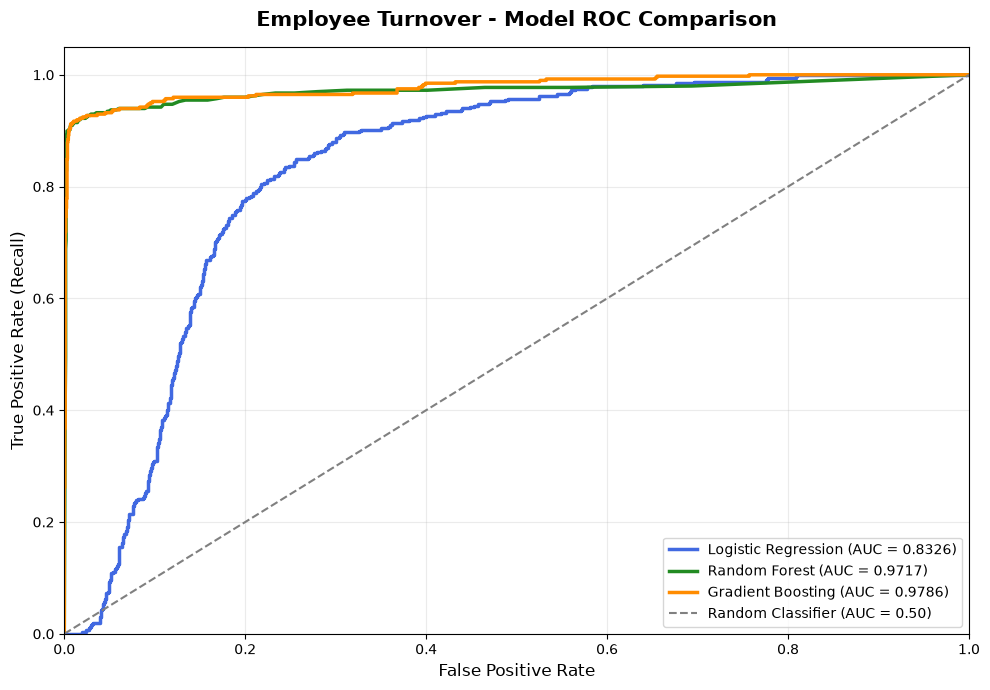

In [81]:
# Create combined ROC visualization
plt.figure(figsize=(10, 7))

# Logistic Regression
plt.plot(
    fpr_logistic,
    tpr_logistic,
    color="royalblue",
    linewidth=2.5,
    label=f"Logistic Regression (AUC = {auc_logistic:.4f})"
)

# Random Forest
plt.plot(
    fpr_forest,
    tpr_forest,
    color="forestgreen",
    linewidth=2.5,
    label=f"Random Forest (AUC = {auc_forest:.4f})"
)

# Gradient Boosting
plt.plot(
    fpr_gradient,
    tpr_gradient,
    color="darkorange",
    linewidth=2.5,
    label=f"Gradient Boosting (AUC = {auc_gradient:.4f})"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

# Professional chart formatting
plt.title(
    "Employee Turnover - Model ROC Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [82]:
def model_findings(name):
    result = model_results[name]
    pred, prob = result["predictions"], result["probabilities"]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cv_result = cv_results_by_model[name]
    metrics = {"accuracy": accuracy_score(y_test, pred),
               "precision": precision_score(y_test, pred),
               "recall": recall_score(y_test, pred),
               "f1": f1_score(y_test, pred),
               "roc_auc": roc_auc_score(y_test, prob)}
    rows = "\n".join(f"| {m} | {cv_result['test_' + m].mean():.4f} | {v:.4f} |"
                     for m, v in metrics.items())
    return (f"### {name} Classification Findings\n\n"
            "Numerical scaling and SMOTE are fitted within each training fold. "
            "The final pipeline is fitted on the original training set.\n\n"
            "| Metric | Mean training CV | Held-out test |\n|---|---:|---:|\n" + rows +
            f"\n\nConfusion matrix: TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}. "
            f"The model identified {tp:,} of {tp+fn:,} actual departures. "
            f"The false-negative rate is {fn/(tp+fn):.2%}; the false-positive rate is {fp/(tn+fp):.2%}.\n\n"
            "Test results are descriptive, not the selection criterion. Earlier test-set exposure "
            "limits their independence. Standard SMOTE can interpolate one-hot indicators, "
            "and discrimination does not establish probability calibration.")

for name in ("Random Forest", "Gradient Boosting"):
    display_markdown(Markdown(model_findings(name)))
best_model = {"Logistic Regression": logistic_pipeline,
              "Random Forest": random_forest_pipeline,
              "Gradient Boosting": gradient_boosting_pipeline}[best_model_name]
display_markdown(Markdown(
    f"### Final Model Selection\n\n**{best_model_name}** was selected using the highest "
    f"mean training-CV recall ({model_ranking_df.loc[0, 'recall']:.2%}). "
    "Recall prioritizes identifying departures; precision tracks the cost of false alarms. "
    "Small model differences have not been tested for statistical significance. "
    "Prior test-set exposure remains a limitation; new untouched data is needed for independent validation."
))


### Random Forest Classification Findings

Numerical scaling and SMOTE are fitted within each training fold. The final pipeline is fitted on the original training set.

| Metric | Mean training CV | Held-out test |
|---|---:|---:|
| accuracy | 0.9818 | 0.9796 |
| precision | 0.9780 | 0.9729 |
| recall | 0.9109 | 0.9020 |
| f1 | 0.9431 | 0.9361 |
| roc_auc | 0.9828 | 0.9717 |

Confusion matrix: TN=1,991, FP=10, FN=39, TP=359. The model identified 359 of 398 actual departures. The false-negative rate is 9.80%; the false-positive rate is 0.50%.

Test results are descriptive, not the selection criterion. Earlier test-set exposure limits their independence. Standard SMOTE can interpolate one-hot indicators, and discrimination does not establish probability calibration.

### Gradient Boosting Classification Findings

Numerical scaling and SMOTE are fitted within each training fold. The final pipeline is fitted on the original training set.

| Metric | Mean training CV | Held-out test |
|---|---:|---:|
| accuracy | 0.9781 | 0.9750 |
| precision | 0.9376 | 0.9311 |
| recall | 0.9303 | 0.9171 |
| f1 | 0.9338 | 0.9241 |
| roc_auc | 0.9866 | 0.9786 |

Confusion matrix: TN=1,974, FP=27, FN=33, TP=365. The model identified 365 of 398 actual departures. The false-negative rate is 8.29%; the false-positive rate is 1.35%.

Test results are descriptive, not the selection criterion. Earlier test-set exposure limits their independence. Standard SMOTE can interpolate one-hot indicators, and discrimination does not establish probability calibration.

### Final Model Selection

**Gradient Boosting** was selected using the highest mean training-CV recall (93.03%). Recall prioritizes identifying departures; precision tracks the cost of false alarms. Small model differences have not been tested for statistical significance. Prior test-set exposure remains a limitation; new untouched data is needed for independent validation.


## Employee Turnover Risk Zones and Retention Strategies

### Objective

The objective of this analysis is to use the
classifier selected by training cross-validation to estimate
employee turnover probabilities.

Predictions will be generated for the held-out
test dataset containing 2,399 employee observations.

Employees will be categorized into four risk zones
based on the predicted probability of leaving:

- Safe Zone (Green): Probability below 20%
- Low-Risk Zone (Yellow): 20% to below 60%
- Medium-Risk Zone (Orange): 60% to below 90%
- High-Risk Zone (Red): 90% and above

Exact boundary values are assigned to the higher
zone to ensure that every prediction is categorized.

The analysis will examine the distribution of
employees across the risk zones and propose
targeted employee retention strategies.

Predicted probabilities are model estimates and
do not establish an employee's actual intention
to leave.


In [83]:
# Create a DataFrame for employee turnover risk analysis
employee_risk_df = X_test.copy()

# Add actual employee turnover status
employee_risk_df["actual_left"] = y_test

# Add predicted turnover probability
employee_risk_df["turnover_probability"] = best_model.predict_proba(X_test)[:, 1]

# Add predicted class
employee_risk_df["predicted_left"] = best_model.predict(X_test)

# Preview the results
employee_risk_df[
    [
        "actual_left",
        "turnover_probability",
        "predicted_left"
    ]
].head(10)

,actual_left,turnover_probability,predicted_left
8569,0,0.294798,0
5747,0,0.227977,0
3985,0,0.014504,0
1776,1,0.927477,1
10499,0,0.022778,0
1533,1,0.967622,1
8554,0,0.095864,0
6154,0,0.016971,0
4230,0,0.002764,0
7910,0,0.012913,0


In [84]:
# Assign risk zones based on turnover probability
def assign_risk_zone(probability):

    if probability < 0.20:
        return "Safe Zone"

    elif probability < 0.60:
        return "Low-Risk Zone"

    elif probability < 0.90:
        return "Medium-Risk Zone"

    else:
        return "High-Risk Zone"


# Apply the function to predicted probabilities
employee_risk_df["risk_zone"] = (
    employee_risk_df["turnover_probability"]
    .apply(assign_risk_zone)
)

# Preview risk-zone assignments
employee_risk_df[
    [
        "turnover_probability",
        "predicted_left",
        "risk_zone"
    ]
].head(10)

,turnover_probability,predicted_left,risk_zone
8569,0.294798,0,Low-Risk Zone
5747,0.227977,0,Low-Risk Zone
3985,0.014504,0,Safe Zone
1776,0.927477,1,High-Risk Zone
10499,0.022778,0,Safe Zone
1533,0.967622,1,High-Risk Zone
8554,0.095864,0,Safe Zone
6154,0.016971,0,Safe Zone
4230,0.002764,0,Safe Zone
7910,0.012913,0,Safe Zone


In [85]:
# Define the desired zone order
zone_order = [
    "Safe Zone",
    "Low-Risk Zone",
    "Medium-Risk Zone",
    "High-Risk Zone"
]

# Count employees in each zone
risk_zone_counts = (
    employee_risk_df["risk_zone"]
    .value_counts()
    .reindex(zone_order, fill_value=0)
)

# Calculate percentages
risk_zone_percentages = (
    risk_zone_counts
    .div(len(employee_risk_df))
    .mul(100)
)

# Create a summary table
risk_zone_summary = pd.DataFrame({
    "Employee Count": risk_zone_counts,
    "Percentage": risk_zone_percentages.round(2)
})

# Display results
risk_zone_summary

,Employee Count,Percentage
risk_zone,,
Safe Zone,1931,80.49
Low-Risk Zone,83,3.46
Medium-Risk Zone,29,1.21
High-Risk Zone,356,14.84


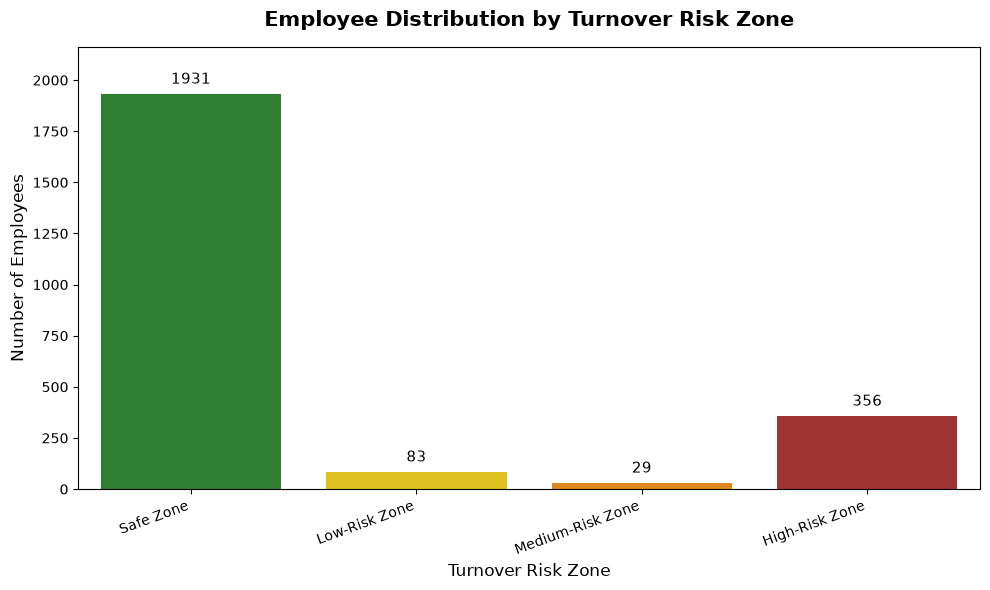

In [86]:
# Define colors for each risk zone
zone_colors = {
    "Safe Zone": "forestgreen",
    "Low-Risk Zone": "gold",
    "Medium-Risk Zone": "darkorange",
    "High-Risk Zone": "firebrick"
}

# Create the bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=risk_zone_summary.index,
    y=risk_zone_summary["Employee Count"],
    hue=risk_zone_summary.index,
    palette=zone_colors,
    legend=False
)

# Add employee counts above the bars
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=11)

# Add chart title and labels
plt.title(
    "Employee Distribution by Turnover Risk Zone",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Turnover Risk Zone", fontsize=12)
plt.ylabel("Number of Employees", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.ylim(0, risk_zone_counts.max() * 1.12)

plt.tight_layout()
plt.show()

In [87]:
# Calculate actual turnover statistics by predicted risk zone
risk_zone_validation = (
    employee_risk_df
    .groupby("risk_zone")["actual_left"]
    .agg(
        Employee_Count="count",
        Actual_Leavers="sum",
        Actual_Turnover_Rate="mean"
    )
    .reindex(zone_order)
)

# Convert actual turnover rate to a percentage
risk_zone_validation["Actual_Turnover_Rate"] *= 100

# Round for readability
risk_zone_validation = risk_zone_validation.round(2)

# Display the results
risk_zone_validation

,Employee_Count,Actual_Leavers,Actual_Turnover_Rate
risk_zone,,,
Safe Zone,1931,27,1.40
Low-Risk Zone,83,7,8.43
Medium-Risk Zone,29,15,51.72
High-Risk Zone,356,349,98.03


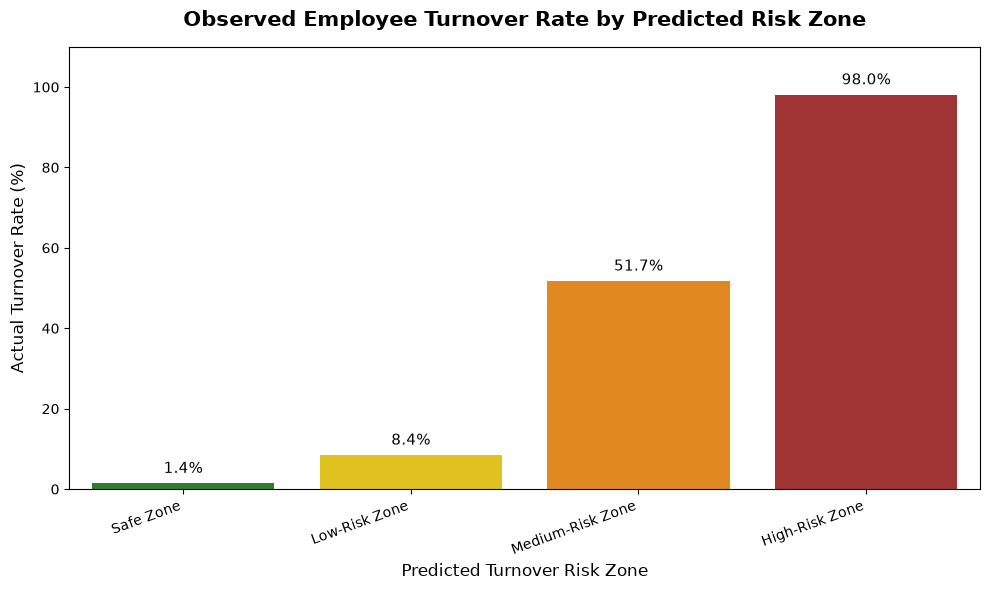

In [88]:
# Create a visualization of actual turnover rates
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=risk_zone_validation.index,
    y=risk_zone_validation["Actual_Turnover_Rate"],
    hue=risk_zone_validation.index,
    palette=zone_colors,
    legend=False
)

# Add actual percentages above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=5,
        fontsize=11
    )

plt.title(
    "Observed Employee Turnover Rate by Predicted Risk Zone",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Turnover Risk Zone", fontsize=12)
plt.ylabel("Actual Turnover Rate (%)", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

In [89]:
# Generate findings directly from the selected model and current risk tables.
rows = []
for zone in zone_order:
    row = risk_zone_validation.loc[zone]
    rows.append(f"| {zone} | {int(row.Employee_Count):,} | "
                f"{risk_zone_summary.loc[zone, 'Percentage']:.2f}% | "
                f"{int(row.Actual_Leavers):,} | {row.Actual_Turnover_Rate:.2f}% |")
display_markdown(Markdown(
    f"### Risk-Zone Findings\n\nSelected model: **{best_model_name}**. "
    f"All {len(employee_risk_df):,} test records receive a zone; exact boundaries enter the higher zone.\n\n"
    "| Zone | Employees | Share | Actual leavers | Observed turnover |\n"
    "|---|---:|---:|---:|---:|\n" + "\n".join(rows) +
    "\n\nThese observed rates describe the historical test sample; they do not prove "
    "that individual probabilities are calibrated. SMOTE alters the training class balance, "
    "so probability calibration on representative validation data is needed before operational use."
))
display_markdown(Markdown('#### Recommended Retention Strategies\n\n**Safe Zone (Green)**\n\nEmployees in this category received predicted\nturnover scores below 20%.\n\nRecommended strategies include:\n\n- Maintain employee engagement and recognition programs.\n- Provide ongoing professional development opportunities.\n- Continue regular employee feedback initiatives.\n- Monitor organizational satisfaction trends.\n\n**Low-Risk Zone (Yellow)**\n\nEmployees in this category received predicted\nturnover scores from 20% to below 60%.\n\nRecommended strategies include:\n\n- Offer voluntary employee engagement discussions.\n- Review career progression and development opportunities.\n- Encourage feedback about workplace satisfaction.\n- Identify emerging organizational concerns.\n\n**Medium-Risk Zone (Orange)**\n\nEmployees in this category received predicted\nturnover scores from 60% to below 90%.\n\nRecommended strategies include:\n\n- Investigate potential workload and role-fit concerns.\n- Review compensation competitiveness where appropriate.\n- Offer personalized career development opportunities.\n- Conduct supportive, voluntary employee feedback sessions.\n- Evaluate organizational factors that may affect retention.\n\n**High-Risk Zone (Red)**\n\nEmployees in this category received predicted\nturnover scores of 90% or higher.\n\nRecommended strategies include:\n\n- Prioritize confidential, voluntary retention discussions.\n- Investigate employee concerns about workload,\n  management, compensation, and career progression.\n- Consider appropriate individualized retention support.\n- Address systemic workplace concerns identified\n  through employee feedback.\n- Avoid punitive employment actions based on model scores.\n\n'))
display_markdown(Markdown(
    "### Final Project Conclusion\n\nAll seven assignment sections are implemented. "
    f"{best_model_name} was selected by training-CV recall. "
    "The model supports exploratory, voluntary retention outreach, not punitive employment decisions. "
    "Deduplication changes the represented population; interpolated categorical indicators, "
    "prior test exposure, and uncalibrated probabilities remain limitations. "
    "Future use requires new-data validation, calibration, fairness and privacy review, and monitoring."
))


### Risk-Zone Findings

Selected model: **Gradient Boosting**. All 2,399 test records receive a zone; exact boundaries enter the higher zone.

| Zone | Employees | Share | Actual leavers | Observed turnover |
|---|---:|---:|---:|---:|
| Safe Zone | 1,931 | 80.49% | 27 | 1.40% |
| Low-Risk Zone | 83 | 3.46% | 7 | 8.43% |
| Medium-Risk Zone | 29 | 1.21% | 15 | 51.72% |
| High-Risk Zone | 356 | 14.84% | 349 | 98.03% |

These observed rates describe the historical test sample; they do not prove that individual probabilities are calibrated. SMOTE alters the training class balance, so probability calibration on representative validation data is needed before operational use.

#### Recommended Retention Strategies

**Safe Zone (Green)**

Employees in this category received predicted
turnover scores below 20%.

Recommended strategies include:

- Maintain employee engagement and recognition programs.
- Provide ongoing professional development opportunities.
- Continue regular employee feedback initiatives.
- Monitor organizational satisfaction trends.

**Low-Risk Zone (Yellow)**

Employees in this category received predicted
turnover scores from 20% to below 60%.

Recommended strategies include:

- Offer voluntary employee engagement discussions.
- Review career progression and development opportunities.
- Encourage feedback about workplace satisfaction.
- Identify emerging organizational concerns.

**Medium-Risk Zone (Orange)**

Employees in this category received predicted
turnover scores from 60% to below 90%.

Recommended strategies include:

- Investigate potential workload and role-fit concerns.
- Review compensation competitiveness where appropriate.
- Offer personalized career development opportunities.
- Conduct supportive, voluntary employee feedback sessions.
- Evaluate organizational factors that may affect retention.

**High-Risk Zone (Red)**

Employees in this category received predicted
turnover scores of 90% or higher.

Recommended strategies include:

- Prioritize confidential, voluntary retention discussions.
- Investigate employee concerns about workload,
  management, compensation, and career progression.
- Consider appropriate individualized retention support.
- Address systemic workplace concerns identified
  through employee feedback.
- Avoid punitive employment actions based on model scores.



### Final Project Conclusion

All seven assignment sections are implemented. Gradient Boosting was selected by training-CV recall. The model supports exploratory, voluntary retention outreach, not punitive employment decisions. Deduplication changes the represented population; interpolated categorical indicators, prior test exposure, and uncalibrated probabilities remain limitations. Future use requires new-data validation, calibration, fairness and privacy review, and monitoring.